## 1. Imports, paths and model settings

In [1]:
from pathlib import Path
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymrio


# ------------------------------------------------------------------
# Paths
# ------------------------------------------------------------------
BASE_DIR = Path(r"C:\Users\menne\Documents\Master\Thesis\Data\MRIO\Exiobase")
STOCK_DIR = BASE_DIR / "stock" 

EXIOBASE_FILE = BASE_DIR / "IOT_2020_pxp.zip"
LEONTIEF_FILE = BASE_DIR / "L_2020_pxp.pkl"
S_PATHWAY_FILE = BASE_DIR / "Emissions" / "EXIOBASE_S_pathway.csv"
REGION_FILE = BASE_DIR / "regions_EXIOBASE.csv"
MATERIAL_PRICE_FILE = BASE_DIR / "material_prices_2020.csv"

# Used only to compare the new sourcing proxy with the previous method.
TECH_IMPORT_FILE = BASE_DIR / "RES_import.csv"       # COMEXT
TECH_PRODUCTION_FILE = BASE_DIR / "RES_production.csv"  # PRODCOM

CAPACITY_FILES = {
    "Linear": STOCK_DIR / "buildout_Linear.csv",
    "Logistic": STOCK_DIR / "buildout_Logistic.csv",
    "Gompertz": STOCK_DIR / "buildout_Gompertz.csv",
}

# These are also outputs of the dynamic-stock workflow. They contain
# country × technology × year × material demand in tonnes.
MATERIAL_FILES = {
    "Linear": STOCK_DIR / "material_demand_Linear.csv",
    "Logistic": STOCK_DIR / "material_demand_Logistic.csv",
    "Gompertz": STOCK_DIR / "material_demand_Gompertz.csv",
}

OUTPUT_DIR = Path(r"C:\Users\menne\Documents\Master\Thesis\output\EE_MRIO_clean")


# ------------------------------------------------------------------
# File settings
# ------------------------------------------------------------------
S_PATHWAY_SEPARATOR = ";"
REGION_SEPARATOR = ";"
MATERIAL_PRICE_SEPARATOR = ";"
TECH_IMPORT_SEPARATOR = ","
TECH_PRODUCTION_SEPARATOR = ","
TECH_SUPPLY_YEAR = 2025
MATERIAL_CHUNKSIZE = 100_000


# ------------------------------------------------------------------
# Sourcing-comparison thresholds
# ------------------------------------------------------------------
# Total variation distance (TVD) ranges from 0 = identical supplier
# distributions to 1 = completely different distributions.
SOURCING_ALERT_TVD = 0.30
SOURCING_ALERT_MAX_POINT_DIFF = 0.25


# ------------------------------------------------------------------
# Example plots: choose one actual model run, not an average SPORE.
# Change after loading the model if desired.
# ------------------------------------------------------------------
SELECTED_GROWTH_MODEL = "Linear"
SELECTED_SPORE = 0
SELECTED_SCENARIO = "Net Zero 2050"
SELECTED_COUNTRY = "NLD"   # dynamic-stock country code
SELECTED_TECH_GROUP = "solar"


# ------------------------------------------------------------------
# Cost assumptions retained from the previous notebook.
# ------------------------------------------------------------------
USD_TO_EUR_2020 = 0.876

MACHINERY_COST_EUR_PER_GW = {
    "solar": 512e6 * USD_TO_EUR_2020,
    "offshore wind": 1210e6 * USD_TO_EUR_2020,
    "onshore wind": 935e6 * USD_TO_EUR_2020,
}


## 2. Load dynamic-stock results

In [2]:
def normalise_tech(value):
    """Return detailed technology label used in the model."""
    text = str(value).strip().lower()
    if "battery" in text or "batter" in text:
        return "battery"
    if "offshore" in text and "wind" in text:
        return "offshore wind"
    if "onshore" in text and "wind" in text:
        return "onshore wind"
    if "wind" in text:
        return "wind"
    if any(term in text for term in ["solar", "photovolta", "pv"]):
        return "solar"
    return text


def tech_supply_group(value):
    tech = normalise_tech(value)
    if tech == "solar":
        return "solar"
    if "wind" in tech:
        return "wind"
    return np.nan


capacity_parts = []
for growth_model, file in CAPACITY_FILES.items():
    part = pd.read_csv(file)
    part["growth_model"] = growth_model
    capacity_parts.append(part)


df_capacity = pd.concat(capacity_parts, ignore_index=True)

required_capacity_cols = {
    "spore", "country", "tech", "year", "new_capacity_required_GW"
}
missing = required_capacity_cols - set(df_capacity.columns)
if missing:
    raise ValueError(f"Dynamic-stock capacity output is missing: {sorted(missing)}")

# Harmonise and remove batteries from the analysis.
df_capacity["tech"] = df_capacity["tech"].map(normalise_tech)
df_capacity = df_capacity.loc[~df_capacity["tech"].eq("battery")].copy()
df_capacity = df_capacity.loc[df_capacity["tech"].isin(["solar", "onshore wind", "offshore wind", "wind"])].copy()

df_capacity["year"] = pd.to_numeric(df_capacity["year"], errors="raise").astype(int)
df_capacity["new_capacity_required_GW"] = pd.to_numeric(
    df_capacity["new_capacity_required_GW"], errors="raise"
)

# Decommissioning does not create negative purchases.
df_capacity["positive_new_capacity_GW"] = df_capacity["new_capacity_required_GW"].clip(lower=0.0)
df_capacity["tech_supply_group"] = df_capacity["tech"].map(tech_supply_group)

# Collapse accidental duplicate rows, if present.
df_capacity = (
    df_capacity
    .groupby(
        ["growth_model", "spore", "country", "tech", "tech_supply_group", "year"],
        as_index=False,
    )[["new_capacity_required_GW", "positive_new_capacity_GW"]]
    .sum()
)

print("Capacity rows:", len(df_capacity))
print("SPOREs:", df_capacity["spore"].nunique())
print("Countries:", df_capacity["country"].nunique())
print("Technologies:", sorted(df_capacity["tech"].unique()))
print("Years:", df_capacity["year"].min(), "-", df_capacity["year"].max())


Capacity rows: 1835343
SPOREs: 441
Countries: 26
Technologies: ['offshore wind', 'onshore wind', 'solar']
Years: 2026 - 2050


The large material-demand files are not concatenated into memory. They are read in chunks when material emissions are calculated. Only the unique technology–material combinations are scanned here to construct the mapping kernel.

In [3]:
MATERIAL_COLUMNS = [
    "spore", "country", "tech", "year", "Material", "material_required_tonnes"
]

tech_material_pairs = set()
for growth_model, file in MATERIAL_FILES.items():
    header = pd.read_csv(file, nrows=0)
    missing = set(MATERIAL_COLUMNS) - set(header.columns)
    if missing:
        raise ValueError(f"{growth_model} material file is missing: {sorted(missing)}")

    for chunk in pd.read_csv(file, usecols=["tech", "Material"], chunksize=MATERIAL_CHUNKSIZE):
        chunk["tech"] = chunk["tech"].map(normalise_tech)
        chunk = chunk.loc[~chunk["tech"].eq("battery")]
        tech_material_pairs.update(
            chunk[["tech", "Material"]].drop_duplicates().itertuples(index=False, name=None)
        )


df_tech_material = pd.DataFrame(tech_material_pairs, columns=["tech", "Material"])
df_tech_material["tech_supply_group"] = df_tech_material["tech"].map(tech_supply_group)
df_tech_material = df_tech_material.loc[df_tech_material["tech_supply_group"].notna()].copy()

print("Technology-material combinations:", len(df_tech_material))
print("Unique materials:", df_tech_material["Material"].nunique())


Technology-material combinations: 45
Unique materials: 22


## 3. Load EXIOBASE, emission-intensity pathways and auxiliary data

In [4]:
# Dynamic emission intensities S_y.
df_S = pd.read_csv(
    S_PATHWAY_FILE,
    sep=S_PATHWAY_SEPARATOR,
    encoding="utf-8-sig",
    usecols=["Region", "sector", "Scenario", "year", "S"],
    low_memory=False,
)
df_S["year"] = pd.to_numeric(df_S["year"], errors="raise").astype(int)
df_S["S"] = pd.to_numeric(df_S["S"], errors="raise")

SCENARIOS = sorted(df_S["Scenario"].dropna().astype(str).unique())
YEARS = sorted(set(df_capacity["year"]) & set(df_S["year"]))

# Country / EXIOBASE-region mapping and material prices.
df_regions = pd.read_csv(REGION_FILE, sep=REGION_SEPARATOR, encoding="utf-8-sig")
df_prices = pd.read_csv(MATERIAL_PRICE_FILE, sep=MATERIAL_PRICE_SEPARATOR, encoding="utf-8-sig")

# EXIOBASE is required for Y (direct mapping) and Z (two-stage sourcing).
exio = pymrio.parse_exiobase3(EXIOBASE_FILE)

print("EXIOBASE regions:", len(exio.get_regions()))
print("EXIOBASE products:", len(exio.get_sectors()))
print("EXIOBASE nodes:", len(exio.x))
print("Emission scenarios:", SCENARIOS)
print("Common model years:", YEARS[0], "-", YEARS[-1])


EXIOBASE regions: 49
EXIOBASE products: 200
EXIOBASE nodes: 9800
Emission scenarios: ['Current Policies', 'Delayed transition', 'Fragmented World', 'Net Zero 2050']
Common model years: 2026 - 2050


## 4. Country and EXIOBASE product mappings

In [5]:
required_region_cols = {"Region", "ISO_2", "ISO_3", "EXIOBASE_region"}
missing = required_region_cols - set(df_regions.columns)
if missing:
    raise ValueError(f"Region mapping is missing columns: {sorted(missing)}")

country_to_exio = (
    df_regions.dropna(subset=["ISO_3", "EXIOBASE_region"])
    .drop_duplicates("ISO_3")
    .assign(ISO_3=lambda d: d["ISO_3"].astype(str).str.upper())
    .set_index("ISO_3")["EXIOBASE_region"]
    .to_dict()
)
iso2_to_exio = (
    df_regions.dropna(subset=["ISO_2", "EXIOBASE_region"])
    .drop_duplicates("ISO_2")
    .assign(ISO_2=lambda d: d["ISO_2"].astype(str).str.upper())
    .set_index("ISO_2")["EXIOBASE_region"]
    .to_dict()
)
name_to_exio = (
    df_regions.dropna(subset=["Region", "EXIOBASE_region"])
    .drop_duplicates("Region")
    .assign(_key=lambda d: d["Region"].astype(str).str.strip().str.upper())
    .set_index("_key")["EXIOBASE_region"]
    .to_dict()
)
EXIO_REGIONS = set(exio.get_regions())


def map_to_exio(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value in EXIO_REGIONS:
        return value
    upper = value.upper()
    return (
        country_to_exio.get(upper)
        or iso2_to_exio.get(upper)
        or name_to_exio.get(upper)
        or np.nan
    )


df_capacity["destination_exio"] = df_capacity["country"].map(map_to_exio)
if df_capacity["destination_exio"].isna().any():
    missing = sorted(df_capacity.loc[df_capacity["destination_exio"].isna(), "country"].unique())
    raise ValueError(f"Capacity countries not mapped to EXIOBASE: {missing}")


products = list(exio.get_sectors())


def resolve_product(preferred, required_terms):
    """Use exact EXIOBASE name when available; otherwise require one unique term match."""
    if preferred in products:
        return preferred
    matches = [
        p for p in products
        if all(term.lower() in p.lower() for term in required_terms)
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Could not uniquely resolve EXIOBASE product {preferred!r}. Candidates: {matches}"
        )
    return matches[0]


WIND_ELECTRICITY_PRODUCT = resolve_product(
    "Electricity by wind", ["electricity", "wind"]
)
SOLAR_ELECTRICITY_PRODUCT = resolve_product(
    "Electricity by solar photovoltaic", ["electricity", "solar", "photovoltaic"]
)
WIND_MACHINERY_PRODUCT = resolve_product(
    "Machinery and equipment n.e.c. (29)", ["machinery", "equipment", "n.e.c."]
)
SOLAR_MACHINERY_PRODUCT = resolve_product(
    "Electrical machinery and apparatus n.e.c. (31)", ["electrical", "machinery", "apparatus"]
)

TECH_STRUCTURE = {
    "wind": {
        "electricity_product": WIND_ELECTRICITY_PRODUCT,
        "machinery_product": WIND_MACHINERY_PRODUCT,
    },
    "solar": {
        "electricity_product": SOLAR_ELECTRICITY_PRODUCT,
        "machinery_product": SOLAR_MACHINERY_PRODUCT,
    },
}

print("Wind electricity:", WIND_ELECTRICITY_PRODUCT)
print("Solar electricity:", SOLAR_ELECTRICITY_PRODUCT)
print("Wind machinery:", WIND_MACHINERY_PRODUCT)
print("Solar machinery:", SOLAR_MACHINERY_PRODUCT)


Wind electricity: Electricity by wind
Solar electricity: Electricity by solar photovoltaic
Wind machinery: Machinery and equipment n.e.c. (29)
Solar machinery: Electrical machinery and apparatus n.e.c. (31)


## 5. Direct mapping: capacity → machinery final demand

For the direct approach, each technology is mapped to one aggregated EXIOBASE machinery product. The monetary machinery demand is geographically distributed using the **gross fixed capital formation (GFCF)** structure of that machinery product in the consuming EU country. This is why the direct mapping does not require a separate material-sourcing model.

For destination country $d$, technology $t$, mapped machinery product $j_t$ and producing region $k$:

\[
w^{FD}_{k|d,t}=\frac{Y^{EXIO}_{(k,j_t),d}}{\sum_{k'}Y^{EXIO}_{(k',j_t),d}}.
\]

In [6]:
def final_demand_supplier_shares(destination_region, product):
    """Producer-region shares of one product in destination-region GFCF."""
    rows = [idx for idx in exio.Y.index if idx[1] == product]
    gfcf_cols = [
        col for col in exio.Y.columns
        if col[0] == destination_region
        and "gross fixed capital formation" in str(col[-1]).lower()
    ]

    if not rows:
        raise KeyError(f"Missing EXIOBASE product rows for {product}")

    # Machinery capacity additions are investment demand, so GFCF is the
    # appropriate final-demand category. If no positive GFCF exists for a
    # country-product pair, use all domestic final-demand categories except
    # exports as an explicit fallback.
    cols = gfcf_cols
    flow = pd.to_numeric(exio.Y.loc[rows, cols].sum(axis=1), errors="coerce").fillna(0.0) if cols else pd.Series(0.0, index=rows)

    if flow.sum() <= 0:
        cols = [
            col for col in exio.Y.columns
            if col[0] == destination_region
            and "exports" not in str(col[-1]).lower()
        ]
        if not cols:
            raise KeyError(f"Missing EXIOBASE final-demand columns for {destination_region}")
        flow = pd.to_numeric(exio.Y.loc[rows, cols].sum(axis=1), errors="coerce").fillna(0.0)
        warnings.warn(
            f"No positive GFCF for {destination_region} | {product}; "
            "using non-export final-demand structure as fallback."
        )

    by_region = flow.groupby(level=0).sum()
    by_region = by_region.loc[by_region > 0]
    total = by_region.sum()
    if total <= 0:
        raise ValueError(f"No positive final demand for {destination_region} | {product}")
    return by_region / total


country_tech = (
    df_capacity[["country", "destination_exio", "tech", "tech_supply_group"]]
    .drop_duplicates()
)

direct_sourcing_parts = []
for row in country_tech.itertuples(index=False):
    product = TECH_STRUCTURE[row.tech_supply_group]["machinery_product"]
    shares = final_demand_supplier_shares(row.destination_exio, product)
    temp = shares.rename("supplier_share").reset_index()
    temp = temp.rename(columns={temp.columns[0]: "supplier_region"})
    temp["country"] = row.country
    temp["destination_exio"] = row.destination_exio
    temp["tech"] = row.tech
    temp["tech_supply_group"] = row.tech_supply_group
    temp["exio_product"] = product
    direct_sourcing_parts.append(temp)


df_direct_sourcing = pd.concat(direct_sourcing_parts, ignore_index=True)

# One column = 1 M.EUR of machinery demand for country × detailed technology.
Y_direct_per_MEUR = (
    df_direct_sourcing
    .pivot_table(
        index=["supplier_region", "exio_product"],
        columns=["country", "tech"],
        values="supplier_share",
        aggfunc="sum",
        fill_value=0.0,
    )
    .reindex(exio.x.index, fill_value=0.0)
)

check = df_direct_sourcing.groupby(["country", "tech"])["supplier_share"].sum()
assert np.allclose(check.to_numpy(), 1.0)
print("Direct-mapping Y kernel:", Y_direct_per_MEUR.shape)


C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for FR | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(
C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for PL | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(
C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for RO | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(
C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for BE | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(


Direct-mapping Y kernel: (9800, 73)


## 6. Material-specific mapping — material prices and products

The material-specific approach keeps the technology-specific physical composition from the dynamic-stock output. Material demand in tonnes is converted to monetary final demand using fixed material prices and mapped to EXIOBASE products.

In [7]:
required_price_cols = {"Material", "price_eur_per_tonne"}
missing = required_price_cols - set(df_prices.columns)
if missing:
    raise ValueError(f"Material-price file is missing: {sorted(missing)}")

df_prices["price_eur_per_tonne"] = pd.to_numeric(df_prices["price_eur_per_tonne"], errors="raise")

if "include_in_mrio" in df_prices.columns:
    include_price = (
        df_prices["include_in_mrio"].astype(str).str.strip().str.lower()
        .isin(["true", "1", "yes", "y"])
    )
else:
    include_price = ~df_prices["Material"].eq("sum of iron")

price_lookup = (
    df_prices.loc[include_price]
    .drop_duplicates("Material")
    .set_index("Material")["price_eur_per_tonne"]
)

# Retained from the previous notebook. Only materials that actually occur
# in wind/solar dynamic-stock outputs are used.
material_to_exio = {
    "iron in steel": "Basic iron and steel and of ferro-alloys and first products thereof",
    "sum of concrete": "Other non-metallic mineral products",
    "non-steel iron": "Basic iron and steel and of ferro-alloys and first products thereof",
    "sum of rare earths": "Other non-ferrous metal products",
    "aluminum": "Aluminium and aluminium products",
    "boron": "Chemicals nec",
    "chromium": "Other non-ferrous metal products",
    "cobalt": "Other non-ferrous metal products",
    "copper": "Copper products",
    "glass and glass-reinforced plastic": "Glass and glass products",
    "graphite": "Chemicals nec",
    "lithium": "Chemicals nec",
    "lead": "Lead, zinc and tin and products thereof",
    "magnesium": "Other non-ferrous metal products",
    "manganese": "Other non-ferrous metal products",
    "molybdenum": "Other non-ferrous metal products",
    "nickel": "Other non-ferrous metal products",
    "niobium": "Other non-ferrous metal products",
    "phosphate": "Chemicals nec",
    "silicon, solar-grade": "Chemicals nec",
    "silver": "Precious metals",
    "solar PV cover glass": "Glass and glass products",
    "tin": "Lead, zinc and tin and products thereof",
    "titanium": "Other non-ferrous metal products",
    "tungsten": "Other non-ferrous metal products",
    "zinc": "Lead, zinc and tin and products thereof",
}

# Allow case-insensitive matching of material names without changing the
# original labels used in the dynamic-stock output.
material_to_exio_ci = {str(k).strip().lower(): v for k, v in material_to_exio.items()}
price_lookup_ci = {str(k).strip().lower(): float(v) for k, v in price_lookup.items()}

df_tech_material["_material_key"] = df_tech_material["Material"].astype(str).str.strip().str.lower()
df_tech_material["exio_product"] = df_tech_material["_material_key"].map(material_to_exio_ci)
df_tech_material["price_eur_per_tonne"] = df_tech_material["_material_key"].map(price_lookup_ci)

# Materials intentionally excluded by the price file are removed. Everything
# else must have an EXIOBASE product mapping.
df_tech_material_model = df_tech_material.loc[df_tech_material["price_eur_per_tonne"].notna()].copy()

if df_tech_material_model["exio_product"].isna().any():
    missing = sorted(df_tech_material_model.loc[df_tech_material_model["exio_product"].isna(), "Material"].unique())
    raise ValueError(f"Materials not mapped to EXIOBASE: {missing}")

missing_products = set(df_tech_material_model["exio_product"]) - set(products)
if missing_products:
    raise ValueError(f"Mapped material products missing from EXIOBASE: {sorted(missing_products)}")

print("Materials included:", df_tech_material_model["Material"].nunique())


Materials included: 22


## 7. Material-specific mapping — sourcing step 1: machinery producers



In [8]:
# ============================================================
# FIRST-STAGE TECHNOLOGY SOURCING
#
# Geographical distribution of machinery supply is determined
# from EXIOBASE final demand (GFCF), using the same sourcing
# method as the direct-mapping approach.
#
# Wind  -> Machinery and equipment n.e.c.
# Solar -> Electrical machinery and apparatus n.e.c.
# ============================================================

# Keep Z available for the SECOND sourcing step
Z = exio.Z


def normalise_region_shares(series):
    values = pd.to_numeric(
        series,
        errors="coerce"
    ).fillna(0.0)

    by_region = values.groupby(level=0).sum()
    by_region = by_region.loc[by_region > 0]

    total = by_region.sum()

    return None if total <= 0 else by_region / total


# ------------------------------------------------------------
# Required country × broad technology combinations
# ------------------------------------------------------------

required_destinations = (
    df_capacity[
        [
            "destination_exio",
            "tech_supply_group"
        ]
    ]
    .drop_duplicates()
)


# ------------------------------------------------------------
# Determine machinery supplier shares from final demand
# ------------------------------------------------------------

sourcing_parts = []

for row in required_destinations.itertuples(index=False):

    machinery_product = (
        TECH_STRUCTURE[
            row.tech_supply_group
        ]["machinery_product"]
    )

    # SAME sourcing function as used for direct mapping
    shares = final_demand_supplier_shares(
        destination_region=row.destination_exio,
        product=machinery_product,
    )

    temp = (
        shares
        .rename("tech_share")
        .reset_index()
    )

    temp = temp.rename(
        columns={
            temp.columns[0]: "manufacturer_region"
        }
    )

    temp["destination_exio"] = (
        row.destination_exio
    )

    temp["tech_supply_group"] = (
        row.tech_supply_group
    )

    temp["machinery_product"] = (
        machinery_product
    )

    temp["sourcing_method"] = (
        "EXIOBASE_final_demand_GFCF"
    )

    sourcing_parts.append(temp)


# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

df_tech_supply_new = pd.concat(
    sourcing_parts,
    ignore_index=True
)


# ------------------------------------------------------------
# Validate
# ------------------------------------------------------------

share_check = (
    df_tech_supply_new
    .groupby(
        [
            "destination_exio",
            "tech_supply_group"
        ]
    )["tech_share"]
    .sum()
)

if not np.allclose(
    share_check.to_numpy(),
    1.0
):
    raise ValueError(
        "First-stage technology sourcing shares "
        "do not sum to 1."
    )


print(
    "First-stage sourcing groups:",
    len(share_check)
)

print(
    "Sourcing method:"
)

display(
    df_tech_supply_new[
        "sourcing_method"
    ]
    .value_counts()
    .rename_axis("method")
    .to_frame("count")
)


display(
    df_tech_supply_new.head(20)
)

C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for FR | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(
C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for PL | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(


First-stage sourcing groups: 52
Sourcing method:


C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for RO | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(
C:\Users\menne\AppData\Local\Temp\ipykernel_16108\386330704.py:29: UserWarning: No positive GFCF for BE | Electrical machinery and apparatus n.e.c. (31); using non-export final-demand structure as fallback.
  warnings.warn(


,count
method,
EXIOBASE_final_demand_GFCF,1275


,manufacturer_region,tech_share,destination_exio,tech_supply_group,machinery_product,sourcing_method
0,AT,9.208315e-01,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
1,BE,1.389299e-03,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
2,CN,6.232968e-11,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
3,CY,1.602400e-06,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
4,CZ,3.934241e-03,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
5,DE,4.631853e-02,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
6,DK,7.893769e-04,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
7,EE,6.800959e-05,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
8,ES,6.718599e-04,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF
9,FI,8.156598e-04,AT,wind,Machinery and equipment n.e.c. (29),EXIOBASE_final_demand_GFCF


## 8. Diagnostic: compare new sourcing with COMEXT + PRODCOM

The previous sourcing proxy combined imports from COMEXT with domestic sold production from PRODCOM. It is **not used in the new CBE calculation**; it is retained only to assess how strongly the new EXIOBASE-based first sourcing step changes the supplier distribution.

The comparison uses **total variation distance**:

\[
TVD_{d,t}=\frac{1}{2}\sum_k |w^{Z}_{k|d,t}-w^{Eurostat}_{k|d,t}|.
\]

A value of 0 means the two supplier distributions are identical; 1 means they do not overlap. The alert thresholds are configurable in Section 1.

In [9]:
# --------------------------------------------------------------
# Load and normalise old COMEXT / PRODCOM sourcing data
# --------------------------------------------------------------
df_import_raw = pd.read_csv(TECH_IMPORT_FILE, sep=TECH_IMPORT_SEPARATOR, encoding="utf-8-sig")
df_production_raw = pd.read_csv(TECH_PRODUCTION_FILE, sep=TECH_PRODUCTION_SEPARATOR, encoding="utf-8-sig")


def normalise_eurostat_technology(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text.endswith(".0"):
        text = text[:-2]
    compact = text.replace(" ", "")
    if compact in {"85414200", "85414300", "85414090"}:
        return "solar"
    if compact == "85023100":
        return "wind"
    if any(k in text for k in ["solar", "photovolta", "pv"]):
        return "solar"
    if "wind" in text:
        return "wind"
    return np.nan


# COMEXT imports
required = {"reporter", "partner", "product", "OBS_VALUE"}
missing = required - set(df_import_raw.columns)
if missing:
    raise ValueError(f"COMEXT file is missing: {sorted(missing)}")

df_import = df_import_raw.copy()
year_col = "year" if "year" in df_import.columns else "TIME_PERIOD" if "TIME_PERIOD" in df_import.columns else None
if TECH_SUPPLY_YEAR is not None and year_col is not None:
    df_import = df_import.loc[pd.to_numeric(df_import[year_col], errors="coerce").eq(TECH_SUPPLY_YEAR)].copy()

df_import["destination_exio"] = df_import["reporter"].map(map_to_exio)
df_import["manufacturer_region"] = df_import["partner"].map(map_to_exio)
df_import["tech_supply_group"] = df_import["product"].map(normalise_eurostat_technology)
df_import["supply_value"] = pd.to_numeric(df_import["OBS_VALUE"], errors="coerce")
df_import = df_import.loc[
    df_import["destination_exio"].notna()
    & df_import["manufacturer_region"].notna()
    & df_import["tech_supply_group"].notna()
    & df_import["supply_value"].ge(0)
].copy()

# PRODCOM domestic production
required = {"reporter", "product", "OBS_VALUE"}
missing = required - set(df_production_raw.columns)
if missing:
    raise ValueError(f"PRODCOM file is missing: {sorted(missing)}")

df_production = df_production_raw.copy()
if "indicators" in df_production.columns:
    df_production = df_production.loc[
        df_production["indicators"].astype(str).str.strip().eq("Sold production value, euro")
    ].copy()
year_col = "year" if "year" in df_production.columns else "TIME_PERIOD" if "TIME_PERIOD" in df_production.columns else None
if TECH_SUPPLY_YEAR is not None and year_col is not None:
    df_production = df_production.loc[
        pd.to_numeric(df_production[year_col], errors="coerce").eq(TECH_SUPPLY_YEAR)
    ].copy()

df_production["destination_exio"] = df_production["reporter"].map(map_to_exio)
df_production["manufacturer_region"] = df_production["destination_exio"]
df_production["tech_supply_group"] = df_production["product"].map(normalise_eurostat_technology)
df_production["supply_value"] = pd.to_numeric(df_production["OBS_VALUE"], errors="coerce")
df_production = df_production.loc[
    df_production["destination_exio"].notna()
    & df_production["tech_supply_group"].notna()
    & df_production["supply_value"].ge(0)
].copy()

# Old supplier shares.
df_tech_supply_old = (
    pd.concat([
        df_import[["destination_exio", "tech_supply_group", "manufacturer_region", "supply_value"]],
        df_production[["destination_exio", "tech_supply_group", "manufacturer_region", "supply_value"]],
    ], ignore_index=True)
    .groupby(["destination_exio", "tech_supply_group", "manufacturer_region"], as_index=False)["supply_value"]
    .sum()
)
df_tech_supply_old["old_total"] = (
    df_tech_supply_old.groupby(["destination_exio", "tech_supply_group"])["supply_value"].transform("sum")
)
df_tech_supply_old = df_tech_supply_old.loc[df_tech_supply_old["old_total"] > 0].copy()
df_tech_supply_old["old_share"] = df_tech_supply_old["supply_value"] / df_tech_supply_old["old_total"]


# --------------------------------------------------------------
# Compare complete supplier distributions
# --------------------------------------------------------------
comparison_long = (
    df_tech_supply_new[["destination_exio", "tech_supply_group", "manufacturer_region", "tech_share"]]
    .rename(columns={"tech_share": "new_share"})
    .merge(
        df_tech_supply_old[["destination_exio", "tech_supply_group", "manufacturer_region", "old_share"]],
        on=["destination_exio", "tech_supply_group", "manufacturer_region"],
        how="outer",
    )
)
comparison_long[["new_share", "old_share"]] = comparison_long[["new_share", "old_share"]].fillna(0.0)
comparison_long["abs_difference"] = (comparison_long["new_share"] - comparison_long["old_share"]).abs()


def sourcing_metrics(group):
    new_top = group.loc[group["new_share"].idxmax(), "manufacturer_region"] if group["new_share"].sum() > 0 else np.nan
    old_top = group.loc[group["old_share"].idxmax(), "manufacturer_region"] if group["old_share"].sum() > 0 else np.nan
    return pd.Series({
        "TVD": 0.5 * group["abs_difference"].sum(),
        "max_supplier_share_difference": group["abs_difference"].max(),
        "new_top_supplier": new_top,
        "old_top_supplier": old_top,
        "top_supplier_changed": new_top != old_top,
    })


df_sourcing_comparison = pd.DataFrame([
    {
        "destination_exio": destination_exio,
        "tech_supply_group": tech_group,
        **sourcing_metrics(group).to_dict(),
    }
    for (destination_exio, tech_group), group in comparison_long.groupby(
        ["destination_exio", "tech_supply_group"]
    )
])

df_sourcing_comparison["alert"] = (
    df_sourcing_comparison["TVD"].ge(SOURCING_ALERT_TVD)
    | df_sourcing_comparison["max_supplier_share_difference"].ge(SOURCING_ALERT_MAX_POINT_DIFF)
)

alerts = df_sourcing_comparison.loc[df_sourcing_comparison["alert"]].sort_values("TVD", ascending=False)
print("Sourcing comparisons:", len(df_sourcing_comparison))
print("Strong-difference alerts:", len(alerts))

if not alerts.empty:
    warnings.warn(
        f"{len(alerts)} sourcing distributions exceed the configured difference threshold. "
        "Inspect df_sourcing_comparison before using the new proxy in the thesis."
    )
    display(alerts.head(30))
else:
    print("No sourcing distribution exceeds the configured thresholds.")


Sourcing comparisons: 54
Strong-difference alerts: 52


C:\Users\menne\AppData\Local\Temp\ipykernel_16108\3535950957.py:140: UserWarning: 52 sourcing distributions exceed the configured difference threshold. Inspect df_sourcing_comparison before using the new proxy in the thesis.
  warnings.warn(


,destination_exio,tech_supply_group,TVD,max_supplier_share_difference,new_top_supplier,old_top_supplier,top_supplier_changed,alert
22,GR,solar,1.000000,1.000000,GR,CN,True,True
0,AT,solar,1.000000,1.000000,AT,DE,True,True
18,FI,solar,1.000000,1.000000,FI,CN,True,True
4,BG,solar,1.000000,1.000000,BG,CN,True,True
44,PT,solar,1.000000,1.000000,PT,CN,True,True
20,FR,solar,1.000000,1.000000,FR,CN,True,True
48,SE,solar,1.000000,1.000000,SE,DE,True,True
51,SI,wind,0.997502,0.917165,SI,CN,True,True
16,ES,solar,0.995422,0.995422,ES,CN,True,True
13,DK,wind,0.981368,0.980263,DE,DK,True,True


## 9. Material-specific mapping — sourcing step 2: material suppliers

For each machinery-producing region $k$, EXIOBASE `Z` is used to determine from which regions $r$ the mapped material $m$ is supplied to machinery production $j_t$:

\[
s_{r|k,m,t}=\frac{Z_{(r,m),(k,j_t)}}{\sum_{r'} Z_{(r',m),(k,j_t)}}.
\]

The two stages are then combined:

\[
q_{r|d,t,m}=\sum_k w_{k|d,t}s_{r|k,m,t}.
\]



In [10]:
material_products = sorted(df_tech_material_model["exio_product"].unique())
material_rows_by_product = {
    product: [idx for idx in Z.index if idx[1] == product]
    for product in material_products
}

# Same fallback hierarchy as the previous notebook, retained for sparse
# manufacturing-region/material combinations.
industry_start = products.index("Products of meat cattle")
industry_end = products.index("Furniture; other manufactured goods n.e.c. (36)")
broad_industry_products = products[industry_start:industry_end + 1]


def get_material_supplier_shares(manufacturing_region, machinery_product, material_product):
    rows = material_rows_by_product[material_product]

    # 1. Preferred: material input directly into the relevant machinery product.
    shares = normalise_region_shares(Z.loc[rows, (manufacturing_region, machinery_product)])
    method = "technology_proxy"

    # 2. Fallback: material inputs to broad industry in the same region.
    if shares is None:
        cols = [(manufacturing_region, p) for p in broad_industry_products]
        shares = normalise_region_shares(Z.loc[rows, cols].sum(axis=1))
        method = "regional_industry_block"

    # 3. Fallback: all intermediate uses in the same region.
    if shares is None:
        cols = [col for col in Z.columns if col[0] == manufacturing_region]
        shares = normalise_region_shares(Z.loc[rows, cols].sum(axis=1))
        method = "regional_all_sectors"

    # 4. Last resort: global material output share.
    if shares is None:
        shares = normalise_region_shares(exio.x.loc[rows].iloc[:, 0])
        method = "global_material_output"

    if shares is None:
        raise ValueError(
            f"No material sourcing available for {manufacturing_region} | "
            f"{machinery_product} | {material_product}"
        )

    result = shares.rename("material_supplier_share").reset_index()
    result = result.rename(columns={result.columns[0]: "material_region"})
    result["supplier_method"] = method
    return result


# Material requirements by broad technology group.
required_materials = (
    df_tech_material_model[["tech_supply_group", "Material", "exio_product"]]
    .drop_duplicates()
)
manufacturer_regions = (
    df_tech_supply_new[["tech_supply_group", "manufacturer_region"]]
    .drop_duplicates()
)
required_combinations = required_materials.merge(manufacturer_regions, on="tech_supply_group", how="inner")

supplier_parts = []
for row in required_combinations.itertuples(index=False):
    machinery_product = TECH_STRUCTURE[row.tech_supply_group]["machinery_product"]
    temp = get_material_supplier_shares(
        manufacturing_region=row.manufacturer_region,
        machinery_product=machinery_product,
        material_product=row.exio_product,
    )
    temp["tech_supply_group"] = row.tech_supply_group
    temp["manufacturer_region"] = row.manufacturer_region
    temp["Material"] = row.Material
    temp["exio_product"] = row.exio_product
    supplier_parts.append(temp)


df_supplier_shares = pd.concat(supplier_parts, ignore_index=True)

# Combine w and s into q.
df_combined_sourcing = (
    df_tech_supply_new[["destination_exio", "tech_supply_group", "manufacturer_region", "tech_share"]]
    .merge(
        df_supplier_shares[[
            "tech_supply_group", "manufacturer_region", "Material", "exio_product",
            "material_region", "material_supplier_share", "supplier_method"
        ]],
        on=["tech_supply_group", "manufacturer_region"],
        how="inner",
        validate="many_to_many",
    )
)
df_combined_sourcing["weighted_supplier_share"] = (
    df_combined_sourcing["tech_share"] * df_combined_sourcing["material_supplier_share"]
)
df_combined_sourcing = (
    df_combined_sourcing
    .groupby(
        ["destination_exio", "tech_supply_group", "Material", "exio_product", "material_region"],
        as_index=False,
    )["weighted_supplier_share"]
    .sum()
    .rename(columns={"weighted_supplier_share": "combined_supplier_share"})
)

check = (
    df_combined_sourcing
    .groupby(["destination_exio", "tech_supply_group", "Material", "exio_product"])["combined_supplier_share"]
    .sum()
)
if not np.allclose(check.to_numpy(), 1.0):
    raise ValueError("Combined material sourcing shares do not sum to 1.")

print("Material sourcing combinations:", len(check))
print("Second-stage fallback methods:")
display(df_supplier_shares["supplier_method"].value_counts().rename_axis("method").to_frame("count"))


Material sourcing combinations: 832
Second-stage fallback methods:


,count
method,
technology_proxy,55670


## 10. Construct final-demand kernels

In [11]:
# ------------------------------------------------------------------
# Material final demand per tonne
# ------------------------------------------------------------------

country_tech_material = (
    country_tech
    .merge(
        df_tech_material_model[
            [
                "tech",
                "tech_supply_group",
                "Material",
                "exio_product",
                "price_eur_per_tonne",
            ]
        ],
        on=["tech", "tech_supply_group"],
        how="inner",
        validate="many_to_many",
    )
)


group_sourcing = (
    country_tech_material
    .merge(
        df_combined_sourcing,
        on=[
            "destination_exio",
            "tech_supply_group",
            "Material",
            "exio_product",
        ],
        how="left",
        validate="many_to_many",
    )
)


if group_sourcing["combined_supplier_share"].isna().any():

    missing = group_sourcing.loc[
        group_sourcing["combined_supplier_share"].isna(),
        [
            "country",
            "tech",
            "Material",
            "destination_exio",
        ],
    ].drop_duplicates()

    display(missing.head(30))

    raise ValueError(
        "Some country-technology-material groups "
        "have no geographical sourcing mix."
    )


# Convert tonnes of material demand into
# M.EUR final demand by supplier region.
group_sourcing["Y_MEUR_per_tonne"] = (
    group_sourcing["combined_supplier_share"]
    * group_sourcing["price_eur_per_tonne"]
    / 1e6
)


MATERIAL_GROUP_COLS = [
    "country",
    "tech",
    "Material",
]


Y_material_per_tonne = (
    group_sourcing
    .pivot_table(
        index=[
            "material_region",
            "exio_product",
        ],
        columns=MATERIAL_GROUP_COLS,
        values="Y_MEUR_per_tonne",
        aggfunc="sum",
        fill_value=0.0,
    )
    .reindex(
        exio.x.index,
        fill_value=0.0
    )
)


print(
    "Material Y kernel:",
    Y_material_per_tonne.shape
)

print(
    "Direct-mapping Y kernel:",
    Y_direct_per_MEUR.shape
)

Material Y kernel: (9800, 1105)
Direct-mapping Y kernel: (9800, 73)


## 11. Load the precomputed Leontief inverse and create production kernels

The Leontief inverse is **loaded, not recalculated**. It is applied only to the two final-demand structures that require full upstream propagation:

- direct technology mapping: $X^{direct}=LY^{direct}$;
- material-specific mapping: $X^{material}=LY^{material}$.

After these kernels are created, the large `L` and `Z` objects are released from memory.

In [12]:
print(
    "Loading precomputed Leontief inverse..."
)

L = pd.read_pickle(
    LEONTIEF_FILE
)


# ------------------------------------------------------------
# Validate node alignment
# ------------------------------------------------------------

if (
    not L.index.equals(exio.x.index)
    or
    not L.columns.equals(exio.x.index)
):

    raise ValueError(
        "Leontief inverse is not aligned "
        "with EXIOBASE nodes."
    )


# ------------------------------------------------------------
# Store column definitions
# ------------------------------------------------------------

MATERIAL_KERNEL_COLUMNS = (
    Y_material_per_tonne.columns.copy()
)

DIRECT_KERNEL_COLUMNS = (
    Y_direct_per_MEUR.columns.copy()
)


# ------------------------------------------------------------
# Convert L to NumPy for faster multiplication
# ------------------------------------------------------------

L_array = L.to_numpy(
    dtype=float,
    copy=False
)


# ------------------------------------------------------------
# Production kernels
#
# X = L Y
# ------------------------------------------------------------

X_material_kernel = (
    L_array
    @
    Y_material_per_tonne.to_numpy(
        dtype=float,
        copy=False
    )
)

X_direct_kernel = (
    L_array
    @
    Y_direct_per_MEUR.to_numpy(
        dtype=float,
        copy=False
    )
)


print(
    "Material production kernel:",
    X_material_kernel.shape
)

print(
    "Direct-mapping production kernel:",
    X_direct_kernel.shape
)


# ------------------------------------------------------------
# Free memory
# ------------------------------------------------------------

del L
del L_array
del Z

exio.Z = None

gc.collect()

Loading precomputed Leontief inverse...
Material production kernel: (9800, 1105)
Direct-mapping production kernel: (9800, 73)


96

## 12. Dynamic emission-intensity accessor and cost demand

In [13]:
def get_S_for_year(
    scenario,
    year
):

    s = (
        df_S.loc[
            df_S["Scenario"]
            .astype(str)
            .eq(str(scenario))
            &
            df_S["year"].eq(int(year)),
            [
                "Region",
                "sector",
                "S",
            ],
        ]
        .drop_duplicates(
            ["Region", "sector"]
        )
        .assign(
            Region=lambda d:
                d["Region"].astype(str),

            sector=lambda d:
                d["sector"].astype(str),
        )
        .set_index(
            ["Region", "sector"]
        )["S"]
        .reindex(exio.x.index)
    )


    if s.isna().any():

        raise ValueError(
            f"Missing emission intensities "
            f"for {scenario}, {year}. "
            f"First missing nodes: "
            f"{list(s.index[s.isna()][:10])}"
        )


    return s.astype(float)


# ============================================================
# DIRECT-MAPPING MONETARY DEMAND
# ============================================================

df_capacity[
    "machinery_cost_EUR_per_GW"
] = (
    df_capacity["tech"]
    .map(
        MACHINERY_COST_EUR_PER_GW
    )
)


if (
    df_capacity[
        "machinery_cost_EUR_per_GW"
    ]
    .isna()
    .any()
):

    missing = sorted(
        df_capacity.loc[
            df_capacity[
                "machinery_cost_EUR_per_GW"
            ].isna(),
            "tech",
        ].unique()
    )

    raise ValueError(
        f"Missing machinery cost "
        f"assumptions for: {missing}"
    )


df_capacity["machinery_MEUR"] = (
    df_capacity[
        "positive_new_capacity_GW"
    ]
    *
    df_capacity[
        "machinery_cost_EUR_per_GW"
    ]
    / 1e6
)

## 13. Precompute annual GHG factors for both mapping approaches

In [14]:
material_factor_parts = []
direct_factor_parts = []


for scenario in SCENARIOS:

    for year in YEARS:

        S_y = get_S_for_year(
            scenario,
            year
        )

        S_array = (
            S_y.to_numpy()
        )


        # ====================================================
        # MATERIAL-SPECIFIC
        #
        # kg CO2-eq per tonne of material demand
        #
        # S × L × Y_material
        # ====================================================

        temp = (
            MATERIAL_KERNEL_COLUMNS
            .to_frame(
                index=False
            )
        )

        temp["Scenario"] = scenario
        temp["year"] = year

        temp[
            "GHG_kgCO2eq_per_tonne"
        ] = (
            S_array
            @
            X_material_kernel
        )

        material_factor_parts.append(
            temp
        )


        # ====================================================
        # DIRECT MAPPING
        #
        # kg CO2-eq per M.EUR machinery demand
        #
        # S × L × Y_machinery
        # ====================================================

        temp = (
            DIRECT_KERNEL_COLUMNS
            .to_frame(
                index=False
            )
        )

        temp["Scenario"] = scenario
        temp["year"] = year

        temp[
            "direct_mapping_kgCO2eq_per_MEUR"
        ] = (
            S_array
            @
            X_direct_kernel
        )

        direct_factor_parts.append(
            temp
        )


df_material_factors = (
    pd.concat(
        material_factor_parts,
        ignore_index=True
    )
)

df_direct_factors = (
    pd.concat(
        direct_factor_parts,
        ignore_index=True
    )
)


print(
    "Material factors:",
    len(df_material_factors)
)

print(
    "Direct-mapping factors:",
    len(df_direct_factors)
)

Material factors: 110500
Direct-mapping factors: 7300


## 14. Calculate material-specific CBE for all dynamic-stock pathways




In [15]:
def calculate_material_emissions(
    file,
    growth_model
):

    parts = []


    for chunk in pd.read_csv(
        file,
        usecols=MATERIAL_COLUMNS,
        chunksize=MATERIAL_CHUNKSIZE,
    ):

        chunk["tech"] = (
            chunk["tech"]
            .map(normalise_tech)
        )

        chunk = (
            chunk.loc[
                ~chunk["tech"].eq(
                    "battery"
                )
            ]
            .copy()
        )


        chunk["year"] = (
            pd.to_numeric(
                chunk["year"],
                errors="raise"
            )
            .astype(int)
        )


        chunk[
            "material_required_tonnes"
        ] = pd.to_numeric(
            chunk[
                "material_required_tonnes"
            ],
            errors="raise"
        )


        # ----------------------------------------------------
        # Keep only mapped materials
        # ----------------------------------------------------

        included_keys = set(
            df_tech_material_model[
                "_material_key"
            ]
        )

        chunk["_material_key"] = (
            chunk["Material"]
            .astype(str)
            .str.strip()
            .str.lower()
        )


        chunk = (
            chunk.loc[
                chunk["_material_key"]
                .isin(included_keys)
            ]
            .copy()
        )


        chunk.drop(
            columns="_material_key",
            inplace=True
        )


        if chunk.empty:
            continue


        # ----------------------------------------------------
        # Add CBE factor per tonne
        # ----------------------------------------------------

        chunk = chunk.merge(
            df_material_factors,
            on=[
                "country",
                "tech",
                "Material",
                "year",
            ],
            how="left",
            validate="many_to_many",
        )


        if (
            chunk[
                "GHG_kgCO2eq_per_tonne"
            ]
            .isna()
            .any()
        ):

            missing = (
                chunk.loc[
                    chunk[
                        "GHG_kgCO2eq_per_tonne"
                    ].isna(),
                    [
                        "country",
                        "tech",
                        "Material",
                        "year",
                    ],
                ]
                .drop_duplicates()
            )

            display(
                missing.head(20)
            )

            raise ValueError(
                "Missing material GHG "
                f"factors in {growth_model}."
            )


        # ----------------------------------------------------
        # Material-specific CBE
        # ----------------------------------------------------

        chunk["GHG_kgCO2eq"] = (
            chunk[
                "material_required_tonnes"
            ]
            *
            chunk[
                "GHG_kgCO2eq_per_tonne"
            ]
        )


        chunk = (
            chunk
            .groupby(
                [
                    "spore",
                    "Scenario",
                    "year",
                    "country",
                    "tech",
                ],
                as_index=False,
            )["GHG_kgCO2eq"]
            .sum()
        )


        parts.append(
            chunk
        )


    # --------------------------------------------------------
    # Combine chunks
    # --------------------------------------------------------

    result = pd.concat(
        parts,
        ignore_index=True
    )


    result = (
        result
        .groupby(
            [
                "spore",
                "Scenario",
                "year",
                "country",
                "tech",
            ],
            as_index=False,
        )["GHG_kgCO2eq"]
        .sum()
    )


    result[
        "growth_model"
    ] = growth_model

    result[
        "component"
    ] = "materials"


    return result


# ============================================================
# ALL GROWTH MODELS
# ============================================================

material_parts = []

for growth_model, file in MATERIAL_FILES.items():

    print(
        "Material emissions:",
        growth_model
    )

    material_parts.append(
        calculate_material_emissions(
            file,
            growth_model
        )
    )


df_material_emissions = (
    pd.concat(
        material_parts,
        ignore_index=True
    )
)


# Material-specific method now contains ONLY
# the explicit material supply chains.
material_specific_components = (
    df_material_emissions[
        [
            "growth_model",
            "spore",
            "Scenario",
            "year",
            "country",
            "tech",
            "component",
            "GHG_kgCO2eq",
        ]
    ]
    .copy()
)


material_specific_components[
    "method"
] = "Material-specific"


material_specific_components[
    "GHG_MtCO2eq"
] = (
    material_specific_components[
        "GHG_kgCO2eq"
    ]
    / 1e9
)


print(
    "Material-specific rows:",
    len(
        material_specific_components
    )
)

Material emissions: Linear
Material emissions: Logistic
Material emissions: Gompertz
Material-specific rows: 7341372


## 15. Calculate direct-mapping CBE for all dynamic-stock pathways



In [16]:
# ============================================================
# DIRECT-MAPPING CBE
# ============================================================

df_direct_method = (
    df_capacity[
        [
            "growth_model",
            "spore",
            "country",
            "tech",
            "year",
            "machinery_MEUR",
        ]
    ]
    .merge(
        df_direct_factors,
        on=[
            "country",
            "tech",
            "year",
        ],
        how="left",
        validate="many_to_many",
    )
)


if (
    df_direct_method[
        "direct_mapping_kgCO2eq_per_MEUR"
    ]
    .isna()
    .any()
):

    raise ValueError(
        "Missing direct-mapping "
        "GHG factors."
    )


# ------------------------------------------------------------
# CBE = monetary machinery demand × full supply-chain factor
# ------------------------------------------------------------

df_direct_method[
    "GHG_kgCO2eq"
] = (
    df_direct_method[
        "machinery_MEUR"
    ]
    *
    df_direct_method[
        "direct_mapping_kgCO2eq_per_MEUR"
    ]
)


df_direct_method[
    "component"
] = "machinery_full_supply_chain"


direct_components = (
    df_direct_method[
        [
            "growth_model",
            "spore",
            "Scenario",
            "year",
            "country",
            "tech",
            "component",
            "GHG_kgCO2eq",
        ]
    ]
    .copy()
)


direct_components[
    "method"
] = "Direct mapping"


direct_components[
    "GHG_MtCO2eq"
] = (
    direct_components[
        "GHG_kgCO2eq"
    ]
    / 1e9
)


# ============================================================
# UNIFIED RESULT TABLE
# ============================================================

df_results = pd.concat(
    [
        material_specific_components,
        direct_components,
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Annual total
# ------------------------------------------------------------

df_annual = (
    df_results
    .groupby(
        [
            "method",
            "growth_model",
            "spore",
            "Scenario",
            "year",
        ],
        as_index=False,
    )["GHG_kgCO2eq"]
    .sum()
)


df_annual[
    "GHG_MtCO2eq"
] = (
    df_annual[
        "GHG_kgCO2eq"
    ]
    / 1e9
)


# ------------------------------------------------------------
# Cumulative 2026-2050 total
# ------------------------------------------------------------

df_cumulative = (
    df_results
    .groupby(
        [
            "method",
            "growth_model",
            "spore",
            "Scenario",
        ],
        as_index=False,
    )["GHG_kgCO2eq"]
    .sum()
)


df_cumulative[
    "GHG_MtCO2eq"
] = (
    df_cumulative[
        "GHG_kgCO2eq"
    ]
    / 1e9
)


print(
    "Result methods:",
    df_results[
        "method"
    ]
    .unique()
    .tolist()
)


print(
    "\nComponents per method:"
)

display(
    df_results[
        ["method", "component"]
    ]
    .drop_duplicates()
)


display(
    df_cumulative.head()
)

Result methods: ['Material-specific', 'Direct mapping']

Components per method:


,method,component
0,Material-specific,materials
7341372,Direct mapping,machinery_full_supply_chain


,method,growth_model,spore,Scenario,GHG_kgCO2eq,GHG_MtCO2eq
0,Direct mapping,Gompertz,0,Current Policies,9.349343e+11,934.934318
1,Direct mapping,Gompertz,0,Delayed transition,8.194560e+11,819.456047
2,Direct mapping,Gompertz,0,Fragmented World,8.788737e+11,878.873704
3,Direct mapping,Gompertz,0,Net Zero 2050,7.050039e+11,705.003875
4,Direct mapping,Gompertz,1,Current Policies,1.048815e+12,1048.815475


## 16. Detailed material-emission breakdown for one selected model run

This helper reconstructs emissions by EXIOBASE emitting region and product only for a chosen growth model, SPORE and emission scenario. It avoids storing a very large region-product result table for every pathway.

In [17]:
EU27_REGIONS = {
    "AT", "BE", "BG", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GR",
    "HR", "HU", "IE", "IT", "LT", "LU", "LV", "MT", "NL", "PL", "PT", "RO",
    "SE", "SI", "SK",
}

node_meta = exio.x.index.to_frame(index=False)
node_meta.columns = ["emission_region", "emission_product"]
node_meta["emission_scope"] = np.where(node_meta["emission_region"].isin(EU27_REGIONS), "EU27", "Non-EU")


def load_selected_material_demand(growth_model, spore):
    file = MATERIAL_FILES[growth_model]
    parts = []
    included_keys = set(df_tech_material_model["_material_key"])

    for chunk in pd.read_csv(file, usecols=MATERIAL_COLUMNS, chunksize=MATERIAL_CHUNKSIZE):
        chunk["tech"] = chunk["tech"].map(normalise_tech)
        chunk = chunk.loc[(chunk["spore"].eq(spore)) & (~chunk["tech"].eq("battery"))].copy()
        chunk["_material_key"] = chunk["Material"].astype(str).str.strip().str.lower()
        chunk = chunk.loc[chunk["_material_key"].isin(included_keys)].copy()
        chunk.drop(columns="_material_key", inplace=True)
        if not chunk.empty:
            parts.append(chunk)

    if not parts:
        raise ValueError(f"No material demand found for {growth_model}, SPORE {spore}.")
    return pd.concat(parts, ignore_index=True)


def material_emission_breakdown(growth_model, spore, scenario):
    detail = load_selected_material_demand(growth_model, spore)
    years = sorted(set(detail["year"].astype(int)) & set(YEARS))

    tonnes = np.zeros((len(MATERIAL_KERNEL_COLUMNS), len(years)))
    for j, year in enumerate(years):
        demand = (
            detail.loc[detail["year"].eq(year)]
            .groupby(MATERIAL_GROUP_COLS)["material_required_tonnes"]
            .sum()
            .reindex(MATERIAL_KERNEL_COLUMNS, fill_value=0.0)
        )
        tonnes[:, j] = demand.to_numpy()

    production = X_material_kernel @ tonnes
    S_matrix = np.column_stack([get_S_for_year(scenario, year).to_numpy() for year in years])
    emissions = S_matrix * production

    out = []
    for j, year in enumerate(years):
        temp = node_meta.copy()
        temp["year"] = year
        temp["GHG_kgCO2eq"] = emissions[:, j]
        out.append(temp)

    result = pd.concat(out, ignore_index=True)
    result["GHG_MtCO2eq"] = result["GHG_kgCO2eq"] / 1e9
    return result


## 17. Example figures — no averages across SPOREs


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ============================================================
# OUTPUT
# ============================================================

CBE_FIG_DIR = Path(
    r"C:\Users\menne\Documents\Master\Thesis\results\CBE"
)

CBE_FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# PLOT ORDER
# ============================================================

GROWTH_ORDER = [
    "Linear",
    "Logistic",
    "Gompertz",
]


# Automatically deal with capitalisation of Delayed Transition
available_scenarios = set(
    df_annual["Scenario"].unique()
)


def resolve_scenario(*names):
    for name in names:
        if name in available_scenarios:
            return name

    raise ValueError(
        f"None of these scenarios found: {names}"
    )


SCENARIO_ORDER = [
    resolve_scenario(
        "Net Zero 2050"
    ),
    resolve_scenario(
        "Current Policies"
    ),
    resolve_scenario(
        "Delayed transition",
        "Delayed Transition",
    ),
    resolve_scenario(
        "Fragmented World"
    ),
]


SCENARIO_LABELS = {
    SCENARIO_ORDER[0]: "Net Zero 2050",
    SCENARIO_ORDER[1]: "Current Policies",
    SCENARIO_ORDER[2]: "Delayed Transition",
    SCENARIO_ORDER[3]: "Fragmented World",
}


METHOD_1 = "Direct mapping"
METHOD_2 = "Material-specific"


# ============================================================
# EU27 PRODUCER REGIONS
#
# This includes Malta as an emitting/supplier region even though
# Malta is absent from the Euro-Calliope capacity pathways.
# ============================================================

EU27_REGIONS = {
    "AT", "BE", "BG", "CY", "CZ", "DE", "DK", "EE",
    "ES", "FI", "FR", "GR", "HR", "HU", "IE", "IT",
    "LT", "LU", "LV", "MT", "NL", "PL", "PT", "RO",
    "SE", "SI", "SK",
}


# ============================================================
# HELPER: SAVE PDF + PNG
# ============================================================

def save_figure(fig, filename):

    fig.savefig(
        CBE_FIG_DIR / f"{filename}.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        CBE_FIG_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight",
    )


# ============================================================
# HELPER: P05 / MEDIAN / P95
# ============================================================

def annual_quantiles(data, method):

    temp = (
        data.loc[
            data["method"].eq(method)
        ]
        .groupby(
            [
                "growth_model",
                "Scenario",
                "year",
            ]
        )["GHG_MtCO2eq"]
        .agg(
            p05=lambda x: x.quantile(0.05),
            median="median",
            p95=lambda x: x.quantile(0.95),
        )
        .reset_index()
    )

    return temp


# ============================================================
# CALCULATE EU PRODUCTION-BASED EMISSION FACTORS
#
# CBE:
#     S_global @ L @ Y
#
# EU production-based component:
#     S_EU @ L @ Y
#
# where S_EU = S for EU27 production nodes
#              0 outside EU27
# ============================================================

node_regions = (
    exio.x.index
    .get_level_values(0)
    .astype(str)
)

eu_node_mask = np.array(
    [
        region in EU27_REGIONS
        for region in node_regions
    ],
    dtype=float,
)


model_years = sorted(
    df_annual["year"]
    .astype(int)
    .unique()
)


material_pbe_factor_parts = []
direct_pbe_factor_parts = []


for scenario in SCENARIO_ORDER:

    for year in model_years:

        S_y = get_S_for_year(
            scenario,
            year,
        )

        S_array = (
            S_y
            .to_numpy(dtype=float)
        )

        # Keep only direct emissions occurring
        # at EU27 EXIOBASE production nodes
        S_EU_array = (
            S_array
            * eu_node_mask
        )


        # ----------------------------------------------------
        # MATERIAL-SPECIFIC PBE FACTORS
        # kg CO2-eq per tonne material demand
        # ----------------------------------------------------

        temp = (
            MATERIAL_KERNEL_COLUMNS
            .to_frame(index=False)
        )

        temp["Scenario"] = scenario
        temp["year"] = year

        temp[
            "PBE_kgCO2eq_per_tonne"
        ] = (
            S_EU_array
            @ X_material_kernel
        )

        material_pbe_factor_parts.append(
            temp
        )


        # ----------------------------------------------------
        # DIRECT-MAPPING PBE FACTORS
        # kg CO2-eq per M.EUR machinery demand
        # ----------------------------------------------------

        temp = (
            DIRECT_KERNEL_COLUMNS
            .to_frame(index=False)
        )

        temp["Scenario"] = scenario
        temp["year"] = year

        temp[
            "PBE_kgCO2eq_per_MEUR"
        ] = (
            S_EU_array
            @ X_direct_kernel
        )

        direct_pbe_factor_parts.append(
            temp
        )


df_material_pbe_factors = pd.concat(
    material_pbe_factor_parts,
    ignore_index=True,
)

df_direct_pbe_factors = pd.concat(
    direct_pbe_factor_parts,
    ignore_index=True,
)


print(
    "Material PBE factors:",
    len(df_material_pbe_factors)
)

print(
    "Direct PBE factors:",
    len(df_direct_pbe_factors)
)

Material PBE factors: 110500
Direct PBE factors: 7300


In [29]:
# ============================================================
# DIRECT-MAPPING PRODUCTION-BASED EMISSIONS
# ============================================================

df_direct_pbe = (
    df_capacity[
        [
            "growth_model",
            "spore",
            "country",
            "tech",
            "year",
            "machinery_MEUR",
        ]
    ]
    .merge(
        df_direct_pbe_factors,
        on=[
            "country",
            "tech",
            "year",
        ],
        how="left",
        validate="many_to_many",
    )
)


if (
    df_direct_pbe[
        "PBE_kgCO2eq_per_MEUR"
    ]
    .isna()
    .any()
):

    raise ValueError(
        "Missing direct-mapping "
        "production-based factors."
    )


df_direct_pbe[
    "GHG_kgCO2eq"
] = (
    df_direct_pbe[
        "machinery_MEUR"
    ]
    *
    df_direct_pbe[
        "PBE_kgCO2eq_per_MEUR"
    ]
)


df_direct_pbe_annual = (
    df_direct_pbe
    .groupby(
        [
            "growth_model",
            "spore",
            "Scenario",
            "year",
        ],
        as_index=False,
    )["GHG_kgCO2eq"]
    .sum()
)


df_direct_pbe_annual[
    "GHG_MtCO2eq"
] = (
    df_direct_pbe_annual[
        "GHG_kgCO2eq"
    ]
    / 1e9
)


df_direct_pbe_annual[
    "method"
] = METHOD_1


# ============================================================
# MATERIAL-SPECIFIC PRODUCTION-BASED EMISSIONS
# ============================================================

included_material_keys = set(
    df_tech_material_model[
        "_material_key"
    ]
)


def calculate_material_pbe(
    file,
    growth_model,
):

    parts = []

    for chunk in pd.read_csv(
        file,
        usecols=MATERIAL_COLUMNS,
        chunksize=MATERIAL_CHUNKSIZE,
    ):

        # -----------------------------------------------
        # Normalise technology
        # -----------------------------------------------

        chunk["tech"] = (
            chunk["tech"]
            .map(normalise_tech)
        )

        chunk = (
            chunk.loc[
                ~chunk["tech"].eq(
                    "battery"
                )
            ]
            .copy()
        )


        # -----------------------------------------------
        # Types
        # -----------------------------------------------

        chunk["year"] = (
            pd.to_numeric(
                chunk["year"],
                errors="raise",
            )
            .astype(int)
        )

        chunk[
            "material_required_tonnes"
        ] = pd.to_numeric(
            chunk[
                "material_required_tonnes"
            ],
            errors="raise",
        )


        # -----------------------------------------------
        # Only materials used by EE-MRIO
        # -----------------------------------------------

        chunk["_material_key"] = (
            chunk["Material"]
            .astype(str)
            .str.strip()
            .str.lower()
        )

        chunk = (
            chunk.loc[
                chunk["_material_key"]
                .isin(
                    included_material_keys
                )
            ]
            .copy()
        )

        chunk.drop(
            columns="_material_key",
            inplace=True,
        )


        if chunk.empty:
            continue


        # -----------------------------------------------
        # Add EU production-based factor
        # -----------------------------------------------

        chunk = chunk.merge(
            df_material_pbe_factors,
            on=[
                "country",
                "tech",
                "Material",
                "year",
            ],
            how="left",
            validate="many_to_many",
        )


        if (
            chunk[
                "PBE_kgCO2eq_per_tonne"
            ]
            .isna()
            .any()
        ):

            raise ValueError(
                "Missing material-specific "
                f"PBE factors for {growth_model}."
            )


        # -----------------------------------------------
        # Production-based emissions
        # -----------------------------------------------

        chunk[
            "GHG_kgCO2eq"
        ] = (
            chunk[
                "material_required_tonnes"
            ]
            *
            chunk[
                "PBE_kgCO2eq_per_tonne"
            ]
        )


        # Aggregate immediately to keep memory use low
        chunk = (
            chunk
            .groupby(
                [
                    "spore",
                    "Scenario",
                    "year",
                ],
                as_index=False,
            )["GHG_kgCO2eq"]
            .sum()
        )

        parts.append(
            chunk
        )


    result = pd.concat(
        parts,
        ignore_index=True,
    )


    result = (
        result
        .groupby(
            [
                "spore",
                "Scenario",
                "year",
            ],
            as_index=False,
        )["GHG_kgCO2eq"]
        .sum()
    )


    result[
        "growth_model"
    ] = growth_model


    result[
        "GHG_MtCO2eq"
    ] = (
        result[
            "GHG_kgCO2eq"
        ]
        / 1e9
    )


    result[
        "method"
    ] = METHOD_2


    return result


material_pbe_parts = []


for growth_model, file in MATERIAL_FILES.items():

    print(
        "Calculating material-specific PBE:",
        growth_model
    )

    material_pbe_parts.append(
        calculate_material_pbe(
            file,
            growth_model,
        )
    )


df_material_pbe_annual = pd.concat(
    material_pbe_parts,
    ignore_index=True,
)


# ============================================================
# COMBINED ANNUAL PBE TABLE
# ============================================================

df_annual_pbe = pd.concat(
    [
        df_direct_pbe_annual,
        df_material_pbe_annual,
    ],
    ignore_index=True,
)


print(
    df_annual_pbe[
        "method"
    ].value_counts()
)

Calculating material-specific PBE: Linear
Calculating material-specific PBE: Logistic
Calculating material-specific PBE: Gompertz
method
Direct mapping       132300
Material-specific    132300
Name: count, dtype: int64


In [63]:
# ============================================================
# COMMON 4 x 3 ANNUAL PLOT
# ============================================================

def plot_annual_deck(
    data,
    method,
    filename,
):

    stats = annual_quantiles(
        data,
        method,
    )


    colour = (
        plt.rcParams[
            "axes.prop_cycle"
        ]
        .by_key()["color"][1]
    )


    fig, axes = plt.subplots(
        nrows=4,
        ncols=3,
        figsize=(12.5, 11),
        sharex=True,
        sharey=True,
    )


    for row, scenario in enumerate(
        SCENARIO_ORDER
    ):

        for col, growth_model in enumerate(
            GROWTH_ORDER
        ):

            ax = axes[
                row,
                col,
            ]


            d = (
                stats.loc[
                    stats["Scenario"].eq(
                        scenario
                    )
                    &
                    stats[
                        "growth_model"
                    ].eq(
                        growth_model
                    )
                ]
                .sort_values(
                    "year"
                )
            )


            ax.fill_between(
                d["year"],
                d["p05"],
                d["p95"],
                alpha=0.20,
                color=colour,
                linewidth=0,
            )


            ax.plot(
                d["year"],
                d["median"],
                color=colour,
                linewidth=1.8,
            )


            ax.grid(
                axis="y",
                alpha=0.20,
            )

            ax.set_axisbelow(
                True
            )


            # Column headers
            if row == 0:

                ax.set_title(
                    growth_model,
                    fontsize=11,
                    fontweight="bold",
                    pad=12,
                )


            # Scenario row labels
            if col == 0:

                ax.text(
                    -0.27,
                    0.5,
                    SCENARIO_LABELS[
                        scenario
                    ],
                    transform=ax.transAxes,
                    rotation=90,
                    va="center",
                    ha="center",
                    fontsize=10,
                    fontweight="bold",
                )


    # x-axis formatting
    for ax in axes[-1, :]:

        ax.set_xticks(
            [
                2026,
                2030,
                2035,
                2040,
                2045,
                2050,
            ]
        )

        ax.set_xlabel(
            "Year"
        )


    fig.supylabel(
        "Annual emissions [Mt CO$_2$-eq]",
        x=0.025,
        fontsize=11,
        fontweight="bold"
    )



    legend_handles = [

        Line2D(
            [0],
            [0],
            color=colour,
            linewidth=1.8,
            label="Median",
        ),

        Patch(
            facecolor=colour,
            alpha=0.20,
            label="5th–95th percentile",
        ),
    ]


    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            0.955,
        ),
        ncol=2,
        frameon=False,
    )


    fig.subplots_adjust(
        left=0.12,
        right=0.98,
        bottom=0.07,
        top=0.90,
        hspace=0.20,
        wspace=0.12,
    )


    save_figure(
        fig,
        filename,
    )

    plt.show()

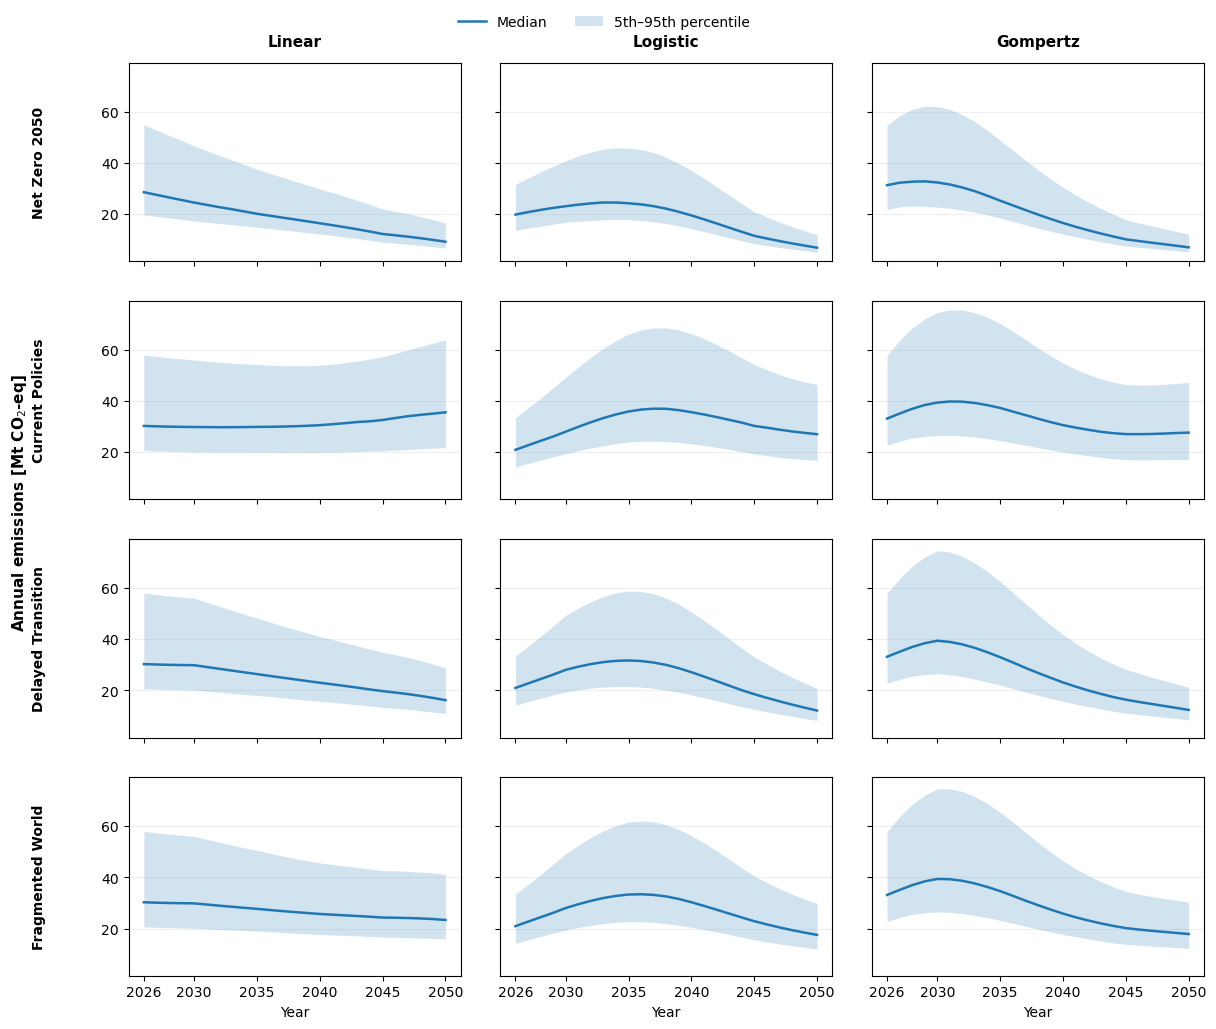

In [42]:
plot_annual_deck(
    data=df_annual,
    method=METHOD_1,
    filename=(
        "01_annual_CBE_direct_mapping"
    ),
)

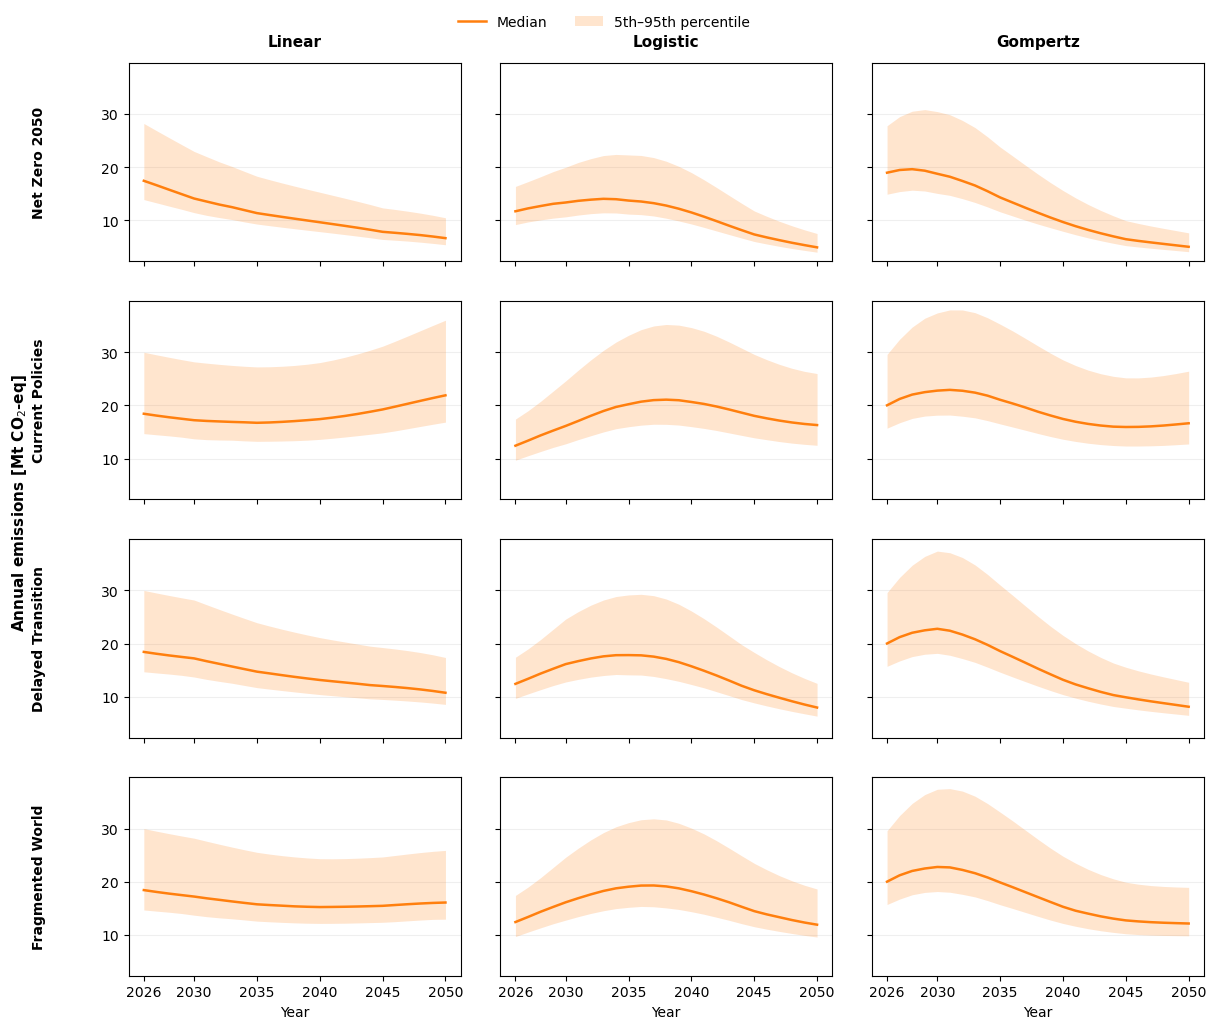

In [64]:
plot_annual_deck(
    data=df_annual,
    method=METHOD_2,
    filename=(
        "02_annual_CBE_material_specific"
    ),
)

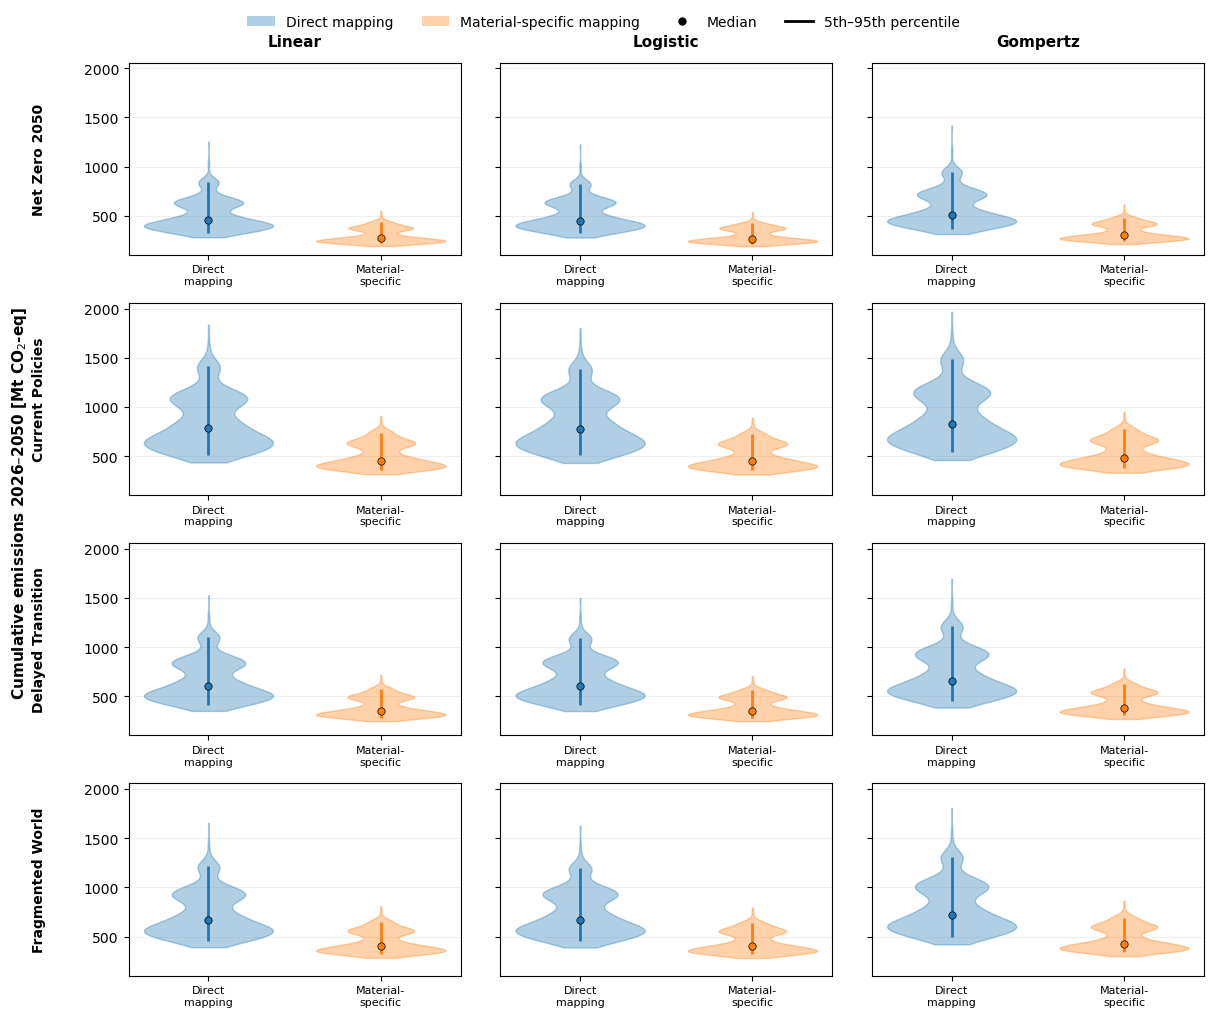

In [49]:
# ============================================================
# FIGURE 3
# CUMULATIVE CBE DISTRIBUTIONS
# ============================================================

method_order = [
    METHOD_1,
    METHOD_2,
]

method_labels = [
    "Direct\nmapping",
    "Material-\nspecific",
]


colours = (
    plt.rcParams[
        "axes.prop_cycle"
    ]
    .by_key()["color"]
)

method_colours = [
    colours[0],
    colours[1],
]


fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(12.5, 11),
    sharey=True,
)


for row, scenario in enumerate(
    SCENARIO_ORDER
):

    for col, growth_model in enumerate(
        GROWTH_ORDER
    ):

        ax = axes[
            row,
            col,
        ]


        distributions = []


        for method in method_order:

            values = (
                df_cumulative.loc[
                    df_cumulative[
                        "method"
                    ].eq(method)
                    &
                    df_cumulative[
                        "growth_model"
                    ].eq(
                        growth_model
                    )
                    &
                    df_cumulative[
                        "Scenario"
                    ].eq(
                        scenario
                    ),
                    "GHG_MtCO2eq",
                ]
                .dropna()
                .to_numpy()
            )

            distributions.append(
                values
            )


        # ----------------------------------------------------
        # Violin
        # ----------------------------------------------------

        violin = ax.violinplot(
            distributions,
            positions=[
                1,
                2,
            ],
            widths=0.75,
            showmeans=False,
            showmedians=False,
            showextrema=False,
        )


        for body, colour in zip(
            violin["bodies"],
            method_colours,
        ):

            body.set_facecolor(
                colour
            )

            body.set_edgecolor(
                colour
            )

            body.set_alpha(
                0.35
            )


        # ----------------------------------------------------
        # P05 / median / P95
        # ----------------------------------------------------

        for position, values, colour in zip(
            [1, 2],
            distributions,
            method_colours,
        ):

            p05 = np.quantile(
                values,
                0.05,
            )

            median = np.median(
                values
            )

            p95 = np.quantile(
                values,
                0.95,
            )


            ax.vlines(
                position,
                p05,
                p95,
                color=colour,
                linewidth=2.0,
            )


            ax.scatter(
                position,
                median,
                color=colour,
                edgecolor="black",
                linewidth=0.5,
                s=28,
                zorder=3,
            )


        ax.set_xticks(
            [
                1,
                2,
            ]
        )

        ax.set_xticklabels(
            method_labels,
            fontsize=8,
        )


        ax.grid(
            axis="y",
            alpha=0.20,
        )

        ax.set_axisbelow(
            True
        )


        if row == 0:

            ax.set_title(
                growth_model,
                fontsize=11,
                fontweight="bold",
                pad=12
            )


        if col == 0:

            ax.text(
                -0.27,
                0.5,
                SCENARIO_LABELS[
                    scenario
                ],
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=10,
                fontweight="bold",
            )


fig.supylabel(
    "Cumulative emissions 2026–2050 [Mt CO$_2$-eq]",
    x=0.025,
    fontweight="bold",
    fontsize=11,
)





legend_handles = [

    Patch(
        facecolor=method_colours[0],
        alpha=0.35,
        label="Direct mapping",
    ),

    Patch(
        facecolor=method_colours[1],
        alpha=0.35,
        label="Material-specific mapping",
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        color="black",
        linestyle="none",
        markersize=5,
        label="Median",
    ),

    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2,
        label="5th–95th percentile",
    ),
]


fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.955,
    ),
    ncol=4,
    frameon=False,
)


fig.subplots_adjust(
    left=0.12,
    right=0.98,
    bottom=0.07,
    top=0.90,
    hspace=0.25,
    wspace=0.12,
)


save_figure(
    fig,
    "03_cumulative_CBE_violin",
)

plt.show()

In [65]:
# ============================================================
# CBE vs EU PRODUCTION-BASED EMISSIONS
# ============================================================

def plot_cbe_vs_pbe(
    method,
    filename,
):

    cbe_stats = annual_quantiles(
        df_annual,
        method,
    )

    pbe_stats = annual_quantiles(
        df_annual_pbe,
        method,
    )


    colours = (
        plt.rcParams[
            "axes.prop_cycle"
        ]
        .by_key()["color"]
    )

    cbe_colour = colours[1]
    pbe_colour = colours[5]


    fig, axes = plt.subplots(
        nrows=4,
        ncols=3,
        figsize=(12.5, 11),
        sharex=True,
        sharey=True,
    )


    for row, scenario in enumerate(
        SCENARIO_ORDER
    ):

        for col, growth_model in enumerate(
            GROWTH_ORDER
        ):

            ax = axes[
                row,
                col,
            ]


            cbe = (
                cbe_stats.loc[
                    cbe_stats[
                        "Scenario"
                    ].eq(
                        scenario
                    )
                    &
                    cbe_stats[
                        "growth_model"
                    ].eq(
                        growth_model
                    )
                ]
                .sort_values(
                    "year"
                )
            )


            pbe = (
                pbe_stats.loc[
                    pbe_stats[
                        "Scenario"
                    ].eq(
                        scenario
                    )
                    &
                    pbe_stats[
                        "growth_model"
                    ].eq(
                        growth_model
                    )
                ]
                .sort_values(
                    "year"
                )
            )


            # ------------------------------------------------
            # CBE
            # ------------------------------------------------

            ax.fill_between(
                cbe["year"],
                cbe["p05"],
                cbe["p95"],
                color=cbe_colour,
                alpha=0.16,
                linewidth=0,
            )


            ax.plot(
                cbe["year"],
                cbe["median"],
                color=cbe_colour,
                linewidth=1.8,
                label="CBE",
            )


            # ------------------------------------------------
            # EU production-based
            # ------------------------------------------------

            ax.fill_between(
                pbe["year"],
                pbe["p05"],
                pbe["p95"],
                color=pbe_colour,
                alpha=0.16,
                linewidth=0,
            )


            ax.plot(
                pbe["year"],
                pbe["median"],
                color=pbe_colour,
                linewidth=1.8,
                linestyle="--",
                label="EU production-based",
            )


            ax.grid(
                axis="y",
                alpha=0.20,
            )

            ax.set_axisbelow(
                True
            )


            if row == 0:

                ax.set_title(
                    growth_model,
                    fontsize=11,
                    fontweight="bold",
                    pad=12
                )


            if col == 0:

                ax.text(
                    -0.27,
                    0.5,
                    SCENARIO_LABELS[
                        scenario
                    ],
                    transform=ax.transAxes,
                    rotation=90,
                    va="center",
                    ha="center",
                    fontsize=10,
                    fontweight="bold",
                )


    for ax in axes[-1, :]:

        ax.set_xticks(
            [
                2026,
                2030,
                2035,
                2040,
                2045,
                2050,
            ]
        )

        ax.set_xlabel(
            "Year"
        )


    fig.supylabel(
        "Annual emissions [Mt CO$_2$-eq]",
        x=0.025,
        fontsize=11,
        fontweight="bold"
    )




    legend_handles = [

        Line2D(
            [0],
            [0],
            color=cbe_colour,
            linewidth=1.8,
            label="Consumption-based emissions",
        ),

        Patch(
            facecolor=cbe_colour,
            alpha=0.16,
            label="CBE 5th–95th percentile",
        ),

        Line2D(
            [0],
            [0],
            color=pbe_colour,
            linewidth=1.8,
            linestyle="--",
            label="EU production-based emissions",
        ),

        Patch(
            facecolor=pbe_colour,
            alpha=0.16,
            label="PBE 5th–95th percentile",
        ),
    ]


    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            0.955,
        ),
        ncol=2,
        frameon=False,
    )


    fig.subplots_adjust(
        left=0.12,
        right=0.98,
        bottom=0.07,
        top=0.89,
        hspace=0.20,
        wspace=0.12,
    )


    save_figure(
        fig,
        filename,
    )

    plt.show()

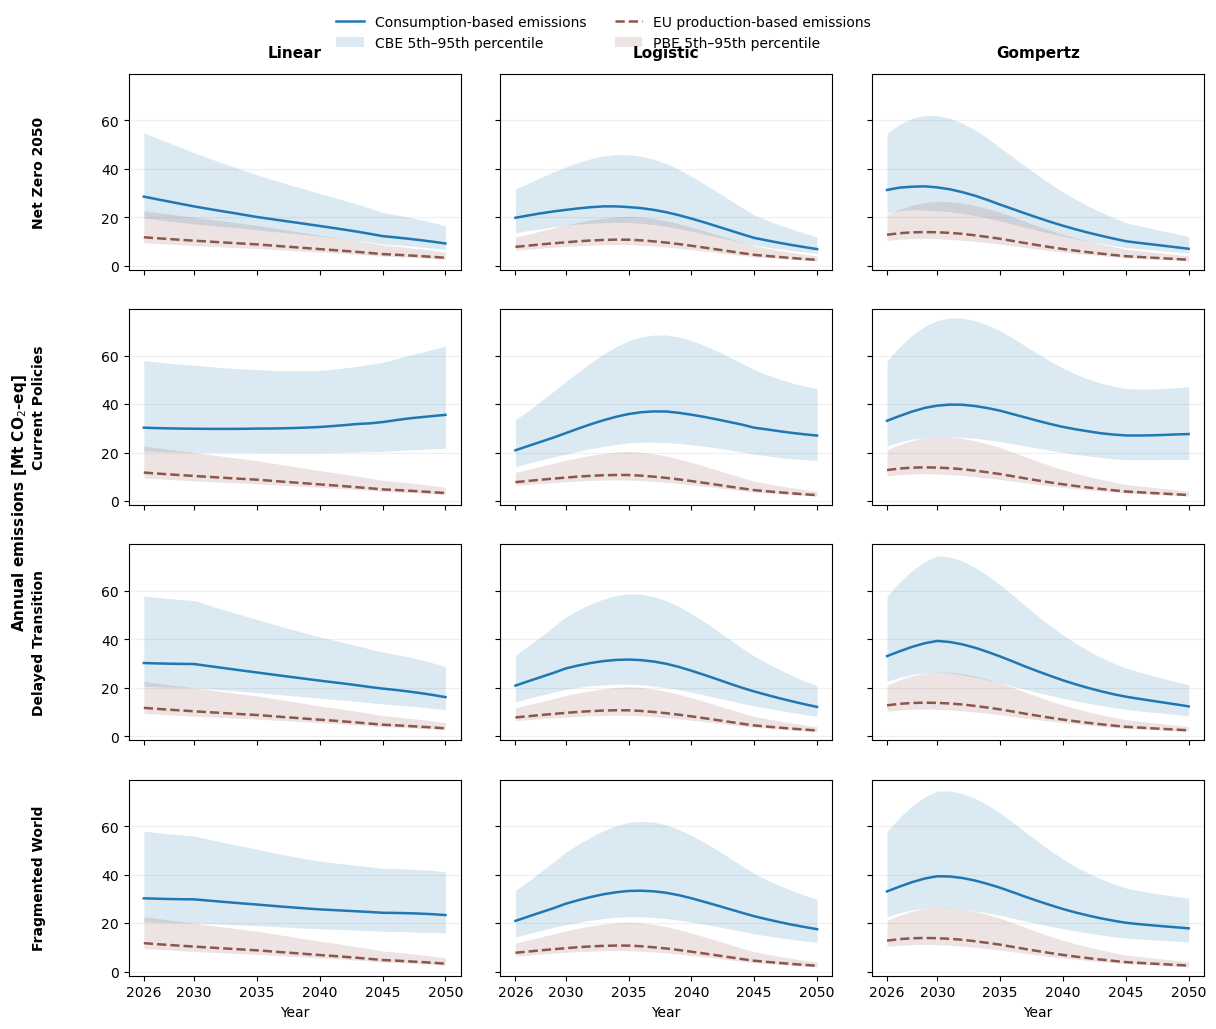

In [61]:
plot_cbe_vs_pbe(
    method=METHOD_1,
    filename=(
        "04_CBE_vs_PBE_direct_mapping"
    ),
)

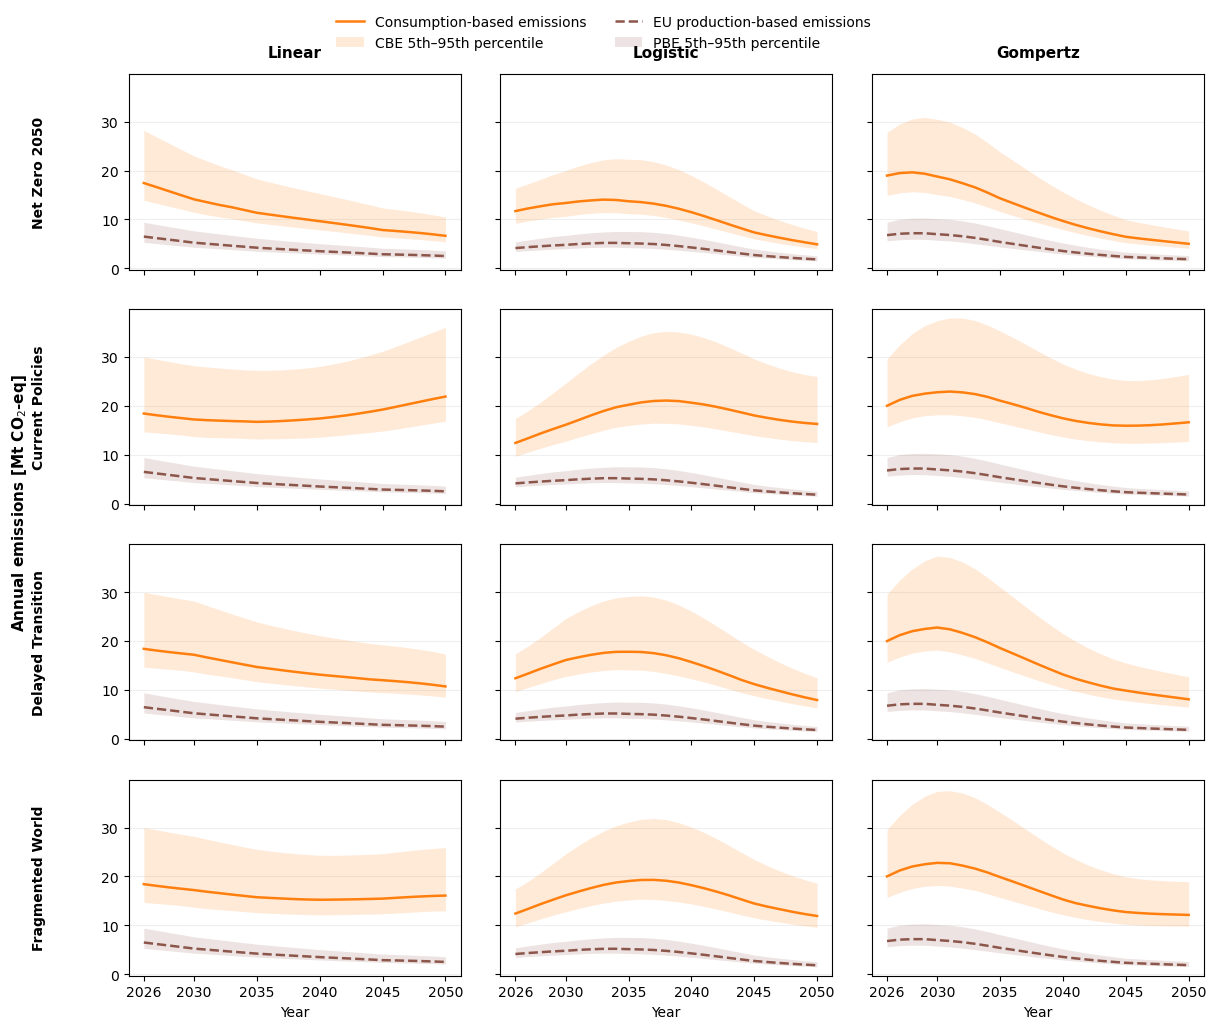

In [66]:
plot_cbe_vs_pbe(
    method=METHOD_2,
    filename=(
        "05_CBE_vs_PBE_material_specific"
    ),
)

Cumulative technology-level observations: 31728

Unique scenarios:
['Current Policies', 'Delayed transition', 'Fragmented World', 'Net Zero 2050']

Number of SPOREs per combination:
Scenario            growth_model  method             tech         
Current Policies    Gompertz      Direct mapping     offshore wind    441
                                                     onshore wind     441
                                                     solar            440
                                  Material-specific  offshore wind    441
                                                     onshore wind     441
                                                     solar            440
                    Linear        Direct mapping     offshore wind    441
                                                     onshore wind     441
                                                     solar            440
                                  Material-specific  offshore wind    441
           

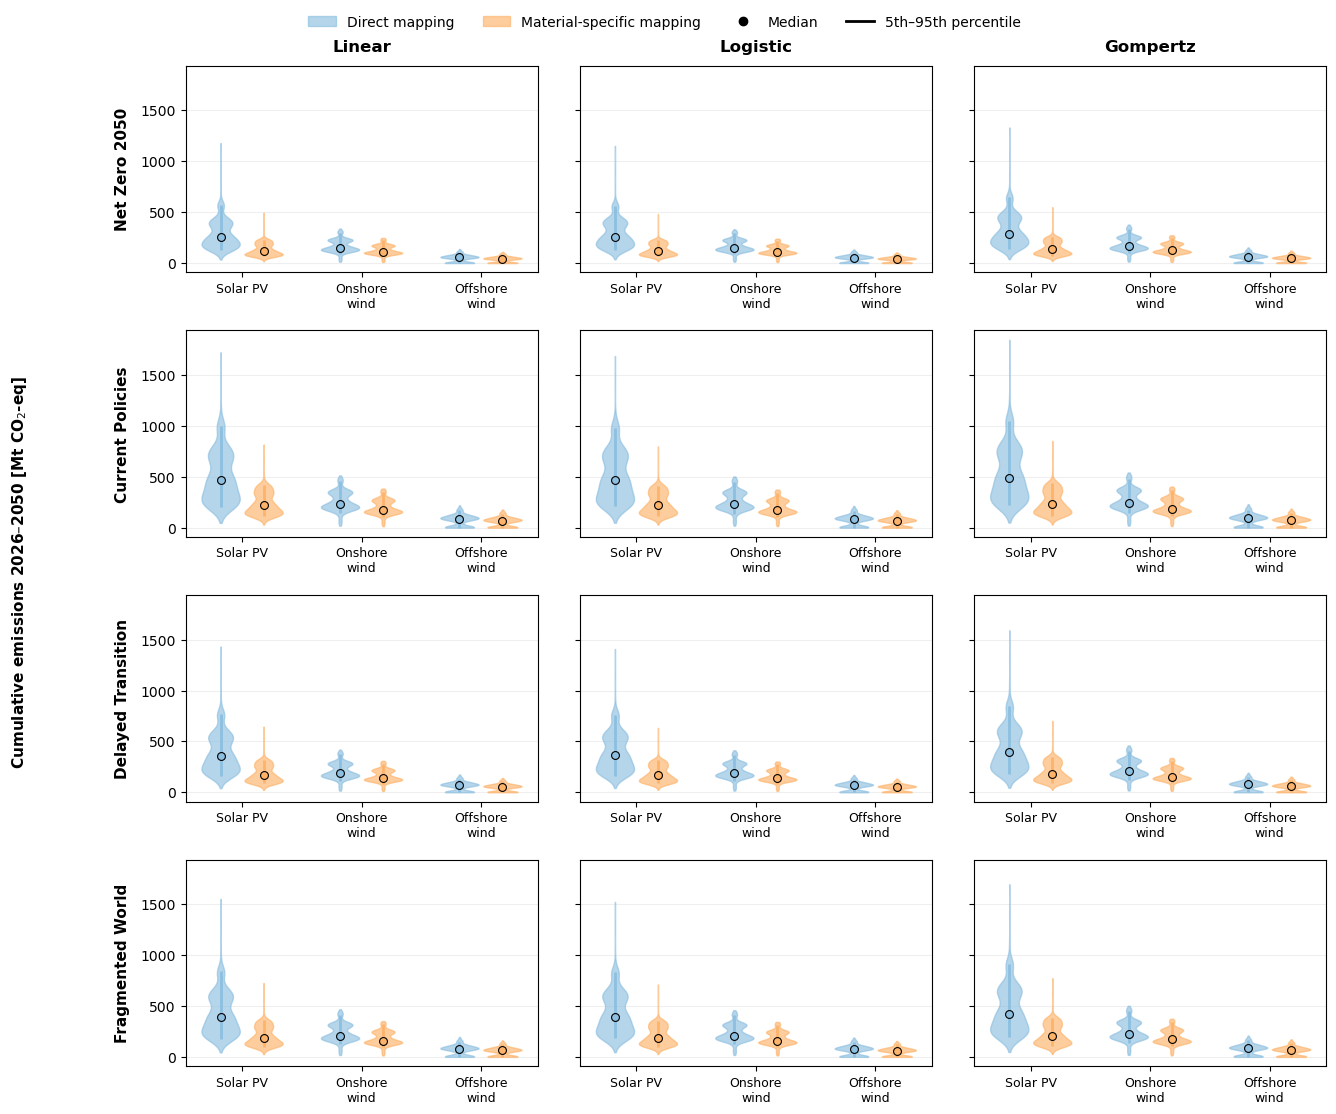

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from pathlib import Path


# ============================================================
# SETTINGS
# ============================================================

output_dir = Path(
    r"C:\Users\menne\Documents\Master\Thesis\results\CBE"
)
output_dir.mkdir(parents=True, exist_ok=True)

scenario_order = [
    "Net Zero 2050",
    "Current Policies",
    "Delayed transition",   # exact spelling in dataframe
    "Fragmented World",
]

scenario_labels = {
    "Net Zero 2050": "Net Zero 2050",
    "Current Policies": "Current Policies",
    "Delayed transition": "Delayed Transition",
    "Fragmented World": "Fragmented World",
}

growth_order = [
    "Linear",
    "Logistic",
    "Gompertz",
]

tech_order = [
    "solar",
    "onshore wind",
    "offshore wind",
]

tech_labels = {
    "solar": "Solar PV",
    "onshore wind": "Onshore\nwind",
    "offshore wind": "Offshore\nwind",
}

method_order = [
    METHOD_1,
    METHOD_2,
]

method_labels = {
    METHOD_1: "Direct mapping",
    METHOD_2: "Material-specific mapping",
}

method_colors = {
    METHOD_1: "#8DBFE0",
    METHOD_2: "#FDB36A",
}

CBE_COL = "GHG_MtCO2eq"


# ============================================================
# CUMULATIVE CBE BY TECHNOLOGY
#
# One violin observation =
# one SPORE × scenario × growth model × method × technology
#
# Sum over:
# - years 2026–2050
# - countries
# - components
# ============================================================

df_tech_cumulative = (
    df_results[
        df_results["tech"].isin(tech_order)
    ]
    .groupby(
        [
            "Scenario",
            "growth_model",
            "spore",
            "method",
            "tech",
        ],
        as_index=False
    )[CBE_COL]
    .sum()
)


# ============================================================
# VALIDATION
# ============================================================

print(
    "Cumulative technology-level observations:",
    len(df_tech_cumulative)
)

print("\nUnique scenarios:")
print(
    df_tech_cumulative["Scenario"]
    .drop_duplicates()
    .tolist()
)

print("\nNumber of SPOREs per combination:")

validation = (
    df_tech_cumulative
    .groupby(
        [
            "Scenario",
            "growth_model",
            "method",
            "tech",
        ]
    )["spore"]
    .nunique()
)

print(validation.to_string())


# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(13.5, 11.5),
    sharey=True,
)

base_positions = np.arange(
    len(tech_order)
)

offset = 0.18

method_offsets = {
    METHOD_1: -offset,
    METHOD_2: +offset,
}

violin_width = 0.32


# ============================================================
# LOOP THROUGH SCENARIOS AND GROWTH MODELS
# ============================================================

for row, scenario in enumerate(scenario_order):

    for col, growth_model in enumerate(growth_order):

        ax = axes[row, col]

        panel = df_tech_cumulative[
            (
                df_tech_cumulative["Scenario"]
                == scenario
            )
            &
            (
                df_tech_cumulative["growth_model"]
                == growth_model
            )
        ]

        # ----------------------------------------------------
        # VIOLINS BY TECHNOLOGY AND METHOD
        # ----------------------------------------------------

        for tech_i, tech in enumerate(tech_order):

            for method in method_order:

                values = (
                    panel[
                        (panel["tech"] == tech)
                        &
                        (panel["method"] == method)
                    ][CBE_COL]
                    .dropna()
                    .to_numpy(dtype=float)
                )

                if len(values) == 0:
                    continue

                x_pos = (
                    base_positions[tech_i]
                    + method_offsets[method]
                )

                # Violin
                vp = ax.violinplot(
                    dataset=[values],
                    positions=[x_pos],
                    widths=violin_width,
                    showmeans=False,
                    showmedians=False,
                    showextrema=False,
                )

                for body in vp["bodies"]:

                    body.set_facecolor(
                        method_colors[method]
                    )

                    body.set_edgecolor(
                        method_colors[method]
                    )

                    body.set_alpha(0.65)

                    body.set_linewidth(1.0)

                # Statistics
                p05 = np.percentile(
                    values,
                    5
                )

                median = np.median(
                    values
                )

                p95 = np.percentile(
                    values,
                    95
                )

                # 5th–95th percentile
                ax.vlines(
                    x=x_pos,
                    ymin=p05,
                    ymax=p95,
                    color=method_colors[method],
                    linewidth=2.0,
                    zorder=4,
                )

                # Median
                ax.scatter(
                    x_pos,
                    median,
                    s=32,
                    color=method_colors[method],
                    edgecolor="black",
                    linewidth=0.8,
                    zorder=5,
                )

        # ----------------------------------------------------
        # AXES
        # ----------------------------------------------------

        ax.set_xticks(
            base_positions
        )

        ax.set_xticklabels(
            [
                tech_labels[t]
                for t in tech_order
            ],
            fontsize=9,
        )

        ax.grid(
            axis="y",
            alpha=0.20,
        )

        ax.set_axisbelow(
            True
        )

        # Growth model headings
        if row == 0:

            ax.set_title(
                growth_model,
                fontsize=12,
                fontweight="bold",
                pad=10,
            )

        # Scenario labels
        if col == 0:

            ax.text(
                -0.18,
                0.5,
                scenario_labels[scenario],
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=11,
                fontweight="bold",
            )


# ============================================================
# COMMON Y LABEL
# ============================================================

fig.supylabel(
    "Cumulative emissions 2026–2050 [Mt CO$_2$-eq]",
    x=0.015,
    fontsize=11,
    fontweight="bold",
)


# ============================================================
# LEGEND
# ============================================================

legend_handles = [

    Patch(
        facecolor=method_colors[METHOD_1],
        edgecolor=method_colors[METHOD_1],
        alpha=0.65,
        label=method_labels[METHOD_1],
    ),

    Patch(
        facecolor=method_colors[METHOD_2],
        edgecolor=method_colors[METHOD_2],
        alpha=0.65,
        label=method_labels[METHOD_2],
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="black",
        markeredgecolor="black",
        markersize=6,
        label="Median",
    ),

    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2,
        label="5th–95th percentile",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=4,
    frameon=False,
    fontsize=10,
)


# ============================================================
# LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.145,
    right=0.99,
    bottom=0.07,
    top=0.94,
    hspace=0.28,
    wspace=0.12,
)


# ============================================================
# SAVE
# ============================================================

fig.savefig(
    output_dir /
    "06_cumulative_CBE_by_technology_violin.pdf",
    bbox_inches="tight",
)

fig.savefig(
    output_dir /
    "06_cumulative_CBE_by_technology_violin.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

Annual comparison dataframe shape: (264600, 6)
Annual stats shape: (600, 7)

Unique scenarios:
['Current Policies', 'Delayed transition', 'Fragmented World', 'Net Zero 2050']

Unique methods:
['Direct mapping', 'Material-specific']


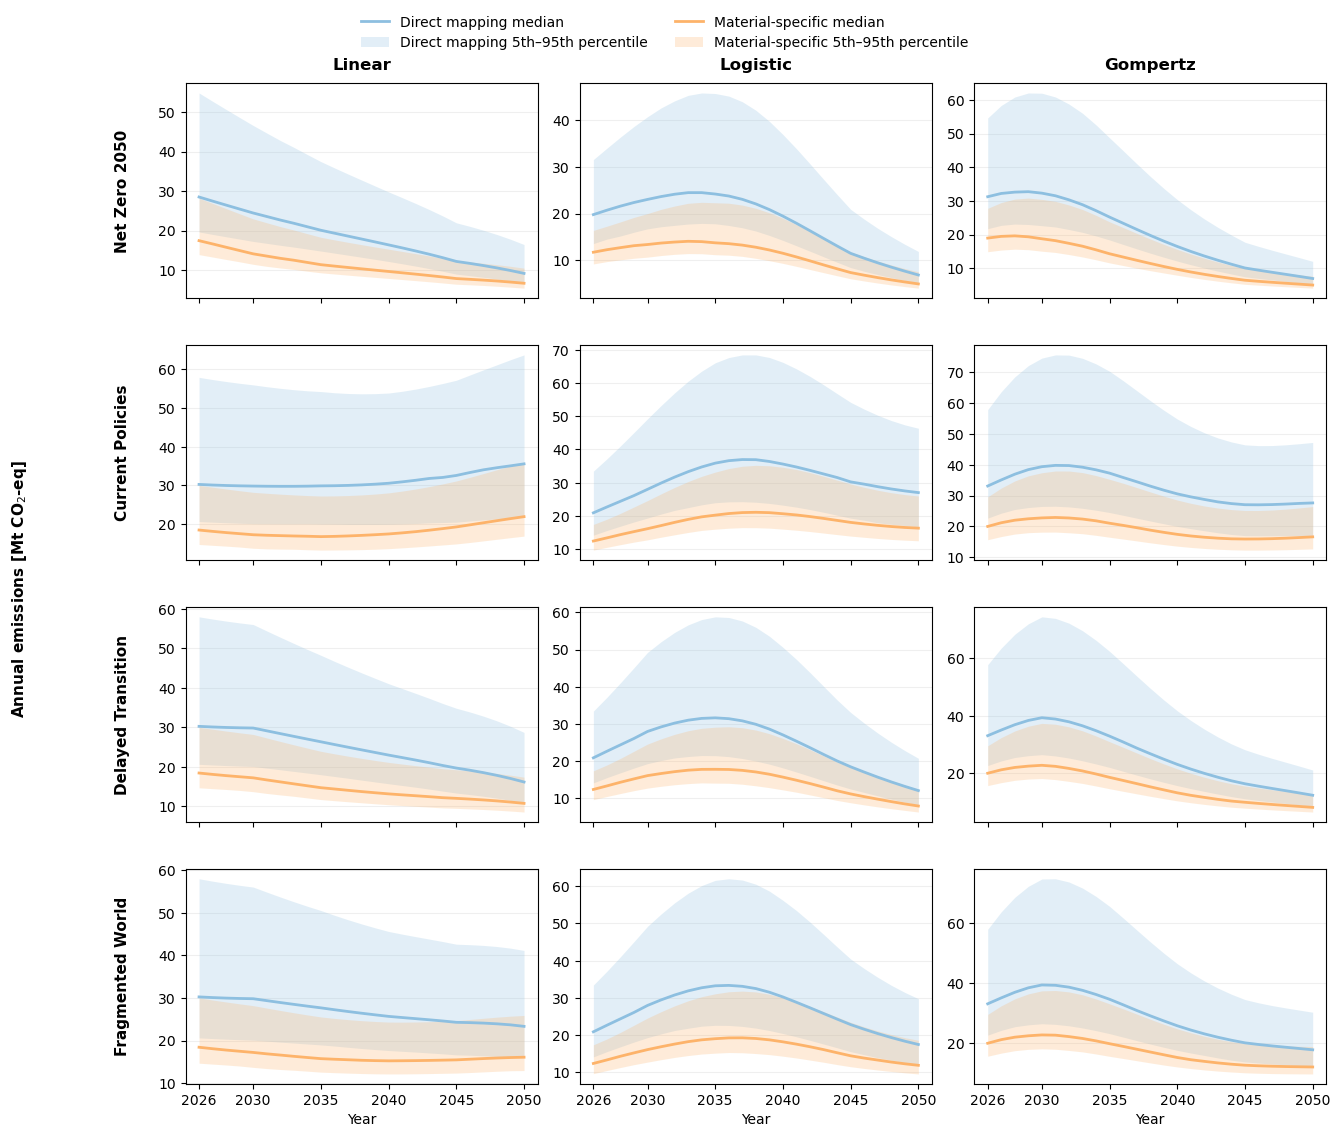

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path

# ============================================================
# SETTINGS
# ============================================================

output_dir = Path(
    r"C:\Users\menne\Documents\Master\Thesis\results\CBE"
)
output_dir.mkdir(parents=True, exist_ok=True)

scenario_order = [
    "Net Zero 2050",
    "Current Policies",
    "Delayed transition",   # exact spelling in dataframe
    "Fragmented World",
]

scenario_labels = {
    "Net Zero 2050": "Net Zero 2050",
    "Current Policies": "Current Policies",
    "Delayed transition": "Delayed Transition",
    "Fragmented World": "Fragmented World",
}

growth_order = [
    "Linear",
    "Logistic",
    "Gompertz",
]

method_order = [
    METHOD_1,
    METHOD_2,
]

method_labels = {
    METHOD_1: "Direct mapping",
    METHOD_2: "Material-specific mapping",
}

method_colors = {
    METHOD_1: "#8DBFE0",
    METHOD_2: "#FDB36A",
}

GHG_COL = "GHG_MtCO2eq"

# ============================================================
# BUILD ANNUAL EU CBE DATA
#
# We aggregate to one annual CBE value per:
# scenario × growth model × method × spore × year
# by summing over countries, technologies and components.
# ============================================================

df_annual_compare = (
    df_results
    .groupby(
        [
            "Scenario",
            "growth_model",
            "method",
            "spore",
            "year",
        ],
        as_index=False
    )[GHG_COL]
    .sum()
)

# ============================================================
# CALCULATE P05 / P50 / P95 ACROSS SPORES
# ============================================================

annual_stats = (
    df_annual_compare
    .groupby(
        [
            "Scenario",
            "growth_model",
            "method",
            "year",
        ]
    )[GHG_COL]
    .quantile([0.05, 0.50, 0.95])
    .unstack()
    .reset_index()
)

annual_stats.columns = [
    "Scenario",
    "growth_model",
    "method",
    "year",
    "p05",
    "p50",
    "p95",
]

# ============================================================
# OPTIONAL VALIDATION
# ============================================================

print("Annual comparison dataframe shape:", df_annual_compare.shape)
print("Annual stats shape:", annual_stats.shape)

print("\nUnique scenarios:")
print(sorted(df_annual_compare["Scenario"].dropna().unique()))

print("\nUnique methods:")
print(sorted(df_annual_compare["method"].dropna().unique()))

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(13.5, 11.5),
    sharex=True,
    sharey=False
)

for row, scenario in enumerate(scenario_order):
    for col, growth_model in enumerate(growth_order):

        ax = axes[row, col]

        panel = annual_stats[
            (annual_stats["Scenario"] == scenario)
            &
            (annual_stats["growth_model"] == growth_model)
        ].copy()

        for method in method_order:

            method_data = (
                panel[panel["method"] == method]
                .sort_values("year")
            )

            if method_data.empty:
                continue

            # 5th-95th percentile band
            ax.fill_between(
                method_data["year"].to_numpy(),
                method_data["p05"].to_numpy(),
                method_data["p95"].to_numpy(),
                color=method_colors[method],
                alpha=0.25,
                linewidth=0
            )

            # median line
            ax.plot(
                method_data["year"].to_numpy(),
                method_data["p50"].to_numpy(),
                color=method_colors[method],
                linewidth=2,
                label=method_labels[method]
            )

        # ----------------------------------------------------
        # Formatting
        # ----------------------------------------------------

        ax.grid(
            axis="y",
            alpha=0.20
        )
        ax.set_axisbelow(True)

        ax.set_xlim(2025, 2051)
        ax.set_xticks([2026, 2030, 2035, 2040, 2045, 2050])

        if row == 0:
            ax.set_title(
                growth_model,
                fontsize=12,
                fontweight="bold",
                pad=10
            )

        if row == len(scenario_order) - 1:
            ax.set_xlabel("Year", fontsize=10)

        if col == 0:
            ax.text(
                -0.18,
                0.5,
                scenario_labels[scenario],
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=11,
                fontweight="bold",
            )

# ============================================================
# COMMON Y LABEL
# ============================================================

fig.supylabel(
    "Annual emissions [Mt CO$_2$-eq]",
    x=0.015,
    fontsize=11,
    fontweight="bold"
)

# ============================================================
# LEGEND
# ============================================================

legend_handles = [
    Line2D(
        [0], [0],
        color=method_colors[METHOD_1],
        lw=2,
        label="Direct mapping median"
    ),
    Patch(
        facecolor=method_colors[METHOD_1],
        edgecolor="none",
        alpha=0.25,
        label="Direct mapping 5th–95th percentile"
    ),
    Line2D(
        [0], [0],
        color=method_colors[METHOD_2],
        lw=2,
        label="Material-specific median"
    ),
    Patch(
        facecolor=method_colors[METHOD_2],
        edgecolor="none",
        alpha=0.25,
        label="Material-specific 5th–95th percentile"
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
    fontsize=10
)

# ============================================================
# LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.145,
    right=0.99,
    bottom=0.07,
    top=0.94,
    hspace=0.22,
    wspace=0.12,
)

# ============================================================
# SAVE
# ============================================================

fig.savefig(
    output_dir / "07_annual_CBE_compare_methods.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "07_annual_CBE_compare_methods.pdf",
    bbox_inches="tight"
)

plt.show()